# Synthetic & Real-World Dataset Exploration

Khảo sát toàn bộ dữ liệu dùng cho tái hiện sMOA bằng Python. Hai phần độc lập: hình thái ba họ synthetic và dữ liệu COVID weekly của 50 bang, gồm historical vintages so với final truth.

Đây là EDA hồi cứu, không phải kết quả forecasting. Không dùng thống kê từ toàn bộ test để tune mô hình. Bảng lấy từ toàn bộ dữ liệu; chỉ các đường minh họa synthetic được chọn làm ví dụ.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
while not (ROOT / 'experiments/exploration').is_dir():
    if ROOT == ROOT.parent: raise RuntimeError('Open notebook inside project')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'experiments/exploration'))
from explore_datasets import run_exploration
SYNTHETIC = ROOT / 'outputs/reproduction_full/01_synthetic/curves.csv'
MANIFEST = ROOT / 'outputs/truth_states/manifest.csv'
ARCHIVE = ROOT / 'outputs/paper_weekly_archive'
POPULATION = ROOT / 'experiments/exploration/reference/state_census_2019.csv'
OUT = ROOT / 'outputs/dataset_exploration'
REBUILD = False  # True: recompute all statistics and figures from raw inputs
if REBUILD or not (OUT / 'progress.json').exists():
    run_exploration(SYNTHETIC, MANIFEST, OUT, archive_dir=ARCHIVE, population=POPULATION)
progress = json.loads((OUT / 'progress.json').read_text())
if progress.get('status') != 'complete': raise RuntimeError('EDA incomplete; rerun with REBUILD=True')
summary = json.loads((OUT / 'summary.json').read_text())
metadata = json.loads((OUT / 'metadata.json').read_text())
display(pd.Series({'Completed UTC': metadata['completed_utc'], 'Python': metadata['python'], **progress}))
def table(area, name): return pd.read_csv(OUT / area / (name + '.csv'))
def figure(area, name): display(Image(filename=str(OUT / area / 'figures' / (name + '.png'))))


Completed UTC       2026-10-30T17:24:02.705500+00:00
Python                                        3.13.5
status                                      complete
synthetic_curves                               54081
states                                            50
figures                                           12
dtype: object

## 1. Synthetic Dataset Exploration

Ba họ: **rollercoaster**, **wiggle**, **seasonal**. Attempts khác accepted curves: seasonal có thể bị loại khi generator không tạo được curve hợp lệ. Thống kê tách theo family × scale × cadence; monthly steps không được coi là weekly steps.

**Đỉnh dịch:** median filter 3 bước; prominence ≥10% khoảng biến thiên của curve; cách nhau ít nhất 4 bước; không đếm hai đầu chuỗi. Có sensitivity 5% và 20%. Đỉnh quan sát không đồng nghĩa số thành phần SIR ẩn.

**Biến động:** mean(|diff|)/mean; thêm CV và SD(diff)/mean. Các chỉ số không đổi khi nhân scale nhưng vẫn có thể chịu ảnh hưởng của rounding, noise và cadence.

In [2]:
display(pd.Series(summary['synthetic']))
groups = table('synthetic', 'groups')
display(groups[['curve_type','scale','time_cadence','curves','observations_median','observations_p10','observations_p90','max_value_median','epidemic_peaks_median','mean_absolute_change_over_mean_median']])

curves                                                                54081
observations                                                       15510156
families                  {'sir_rollercoaster': 18387, 'sir_rollercoaste...
attempts                                                              55161
accepted                                                              54081
embedding_windows_keep                                             15023012
embedding_windows_omit                                             14968931
peak_rule                 {'smoothing': 'centered median of 3 original s...
k                                                                         5
h                                                                         4
dtype: object

,curve_type,scale,time_cadence,curves,observations_median,observations_p10,observations_p90,max_value_median,epidemic_peaks_median,mean_absolute_change_over_mean_median
0,sir_rollercoaster,counts,weekly,9114,263.0,164.0,466.0,210954.500000,4.0,0.204329
1,sir_rollercoaster,proportion,weekly,9273,265.0,165.0,475.0,0.011122,4.0,0.203350
2,sir_rollercoaster_wiggle,proportion,weekly,9128,263.0,162.0,469.0,0.011185,4.0,0.208686
3,sir_rollercoaster_wiggle,counts,weekly,9259,262.0,163.0,472.0,204750.000000,4.0,0.207901
4,seasonal,proportion,monthly,4288,111.0,59.0,163.0,0.010783,7.0,0.516080
5,seasonal,counts,weekly,4390,441.0,233.0,649.0,205077.000000,8.0,0.234198
6,seasonal,proportion,weekly,4322,441.0,233.0,649.0,0.012036,8.0,0.236812
7,seasonal,counts,monthly,4307,111.0,59.0,163.0,194111.000000,7.0,0.514406


### Hình dạng, độ dài và số đỉnh
Các ví dụ chia cho peak riêng để thấy hình dạng; không dùng phép chuẩn hóa này cho forecasting. Boxplots bỏ marker outlier để đọc hình, giữ mọi quan sát khi tính thống kê.

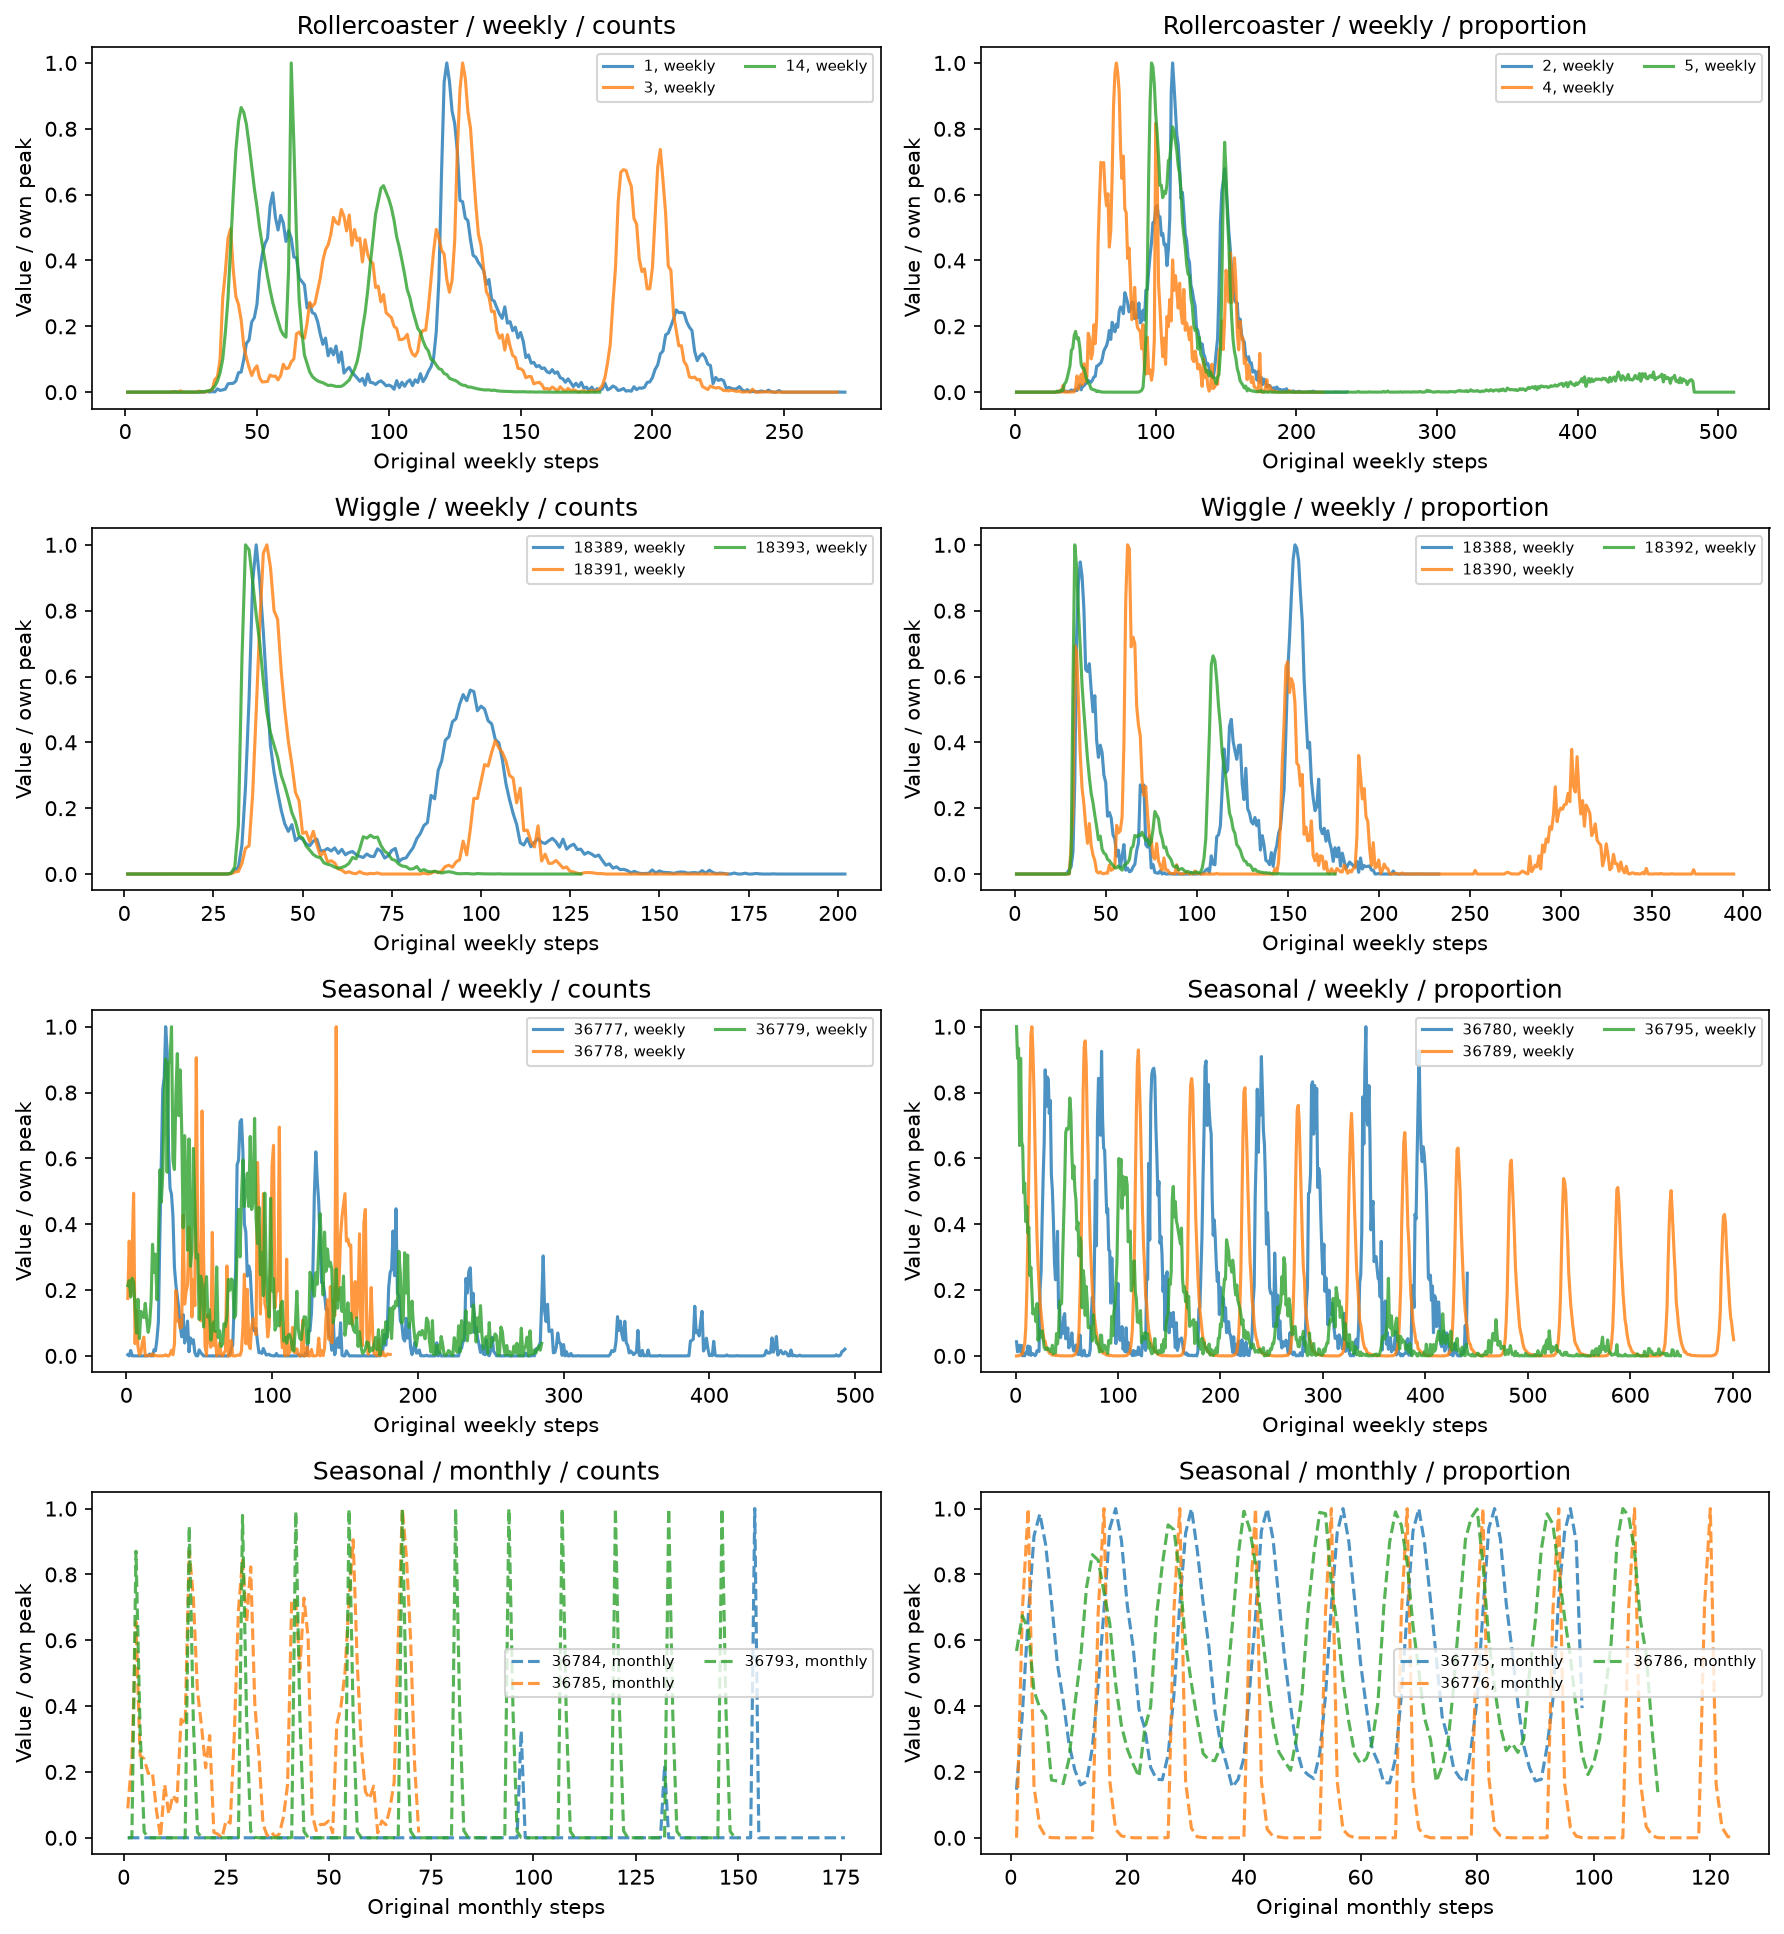

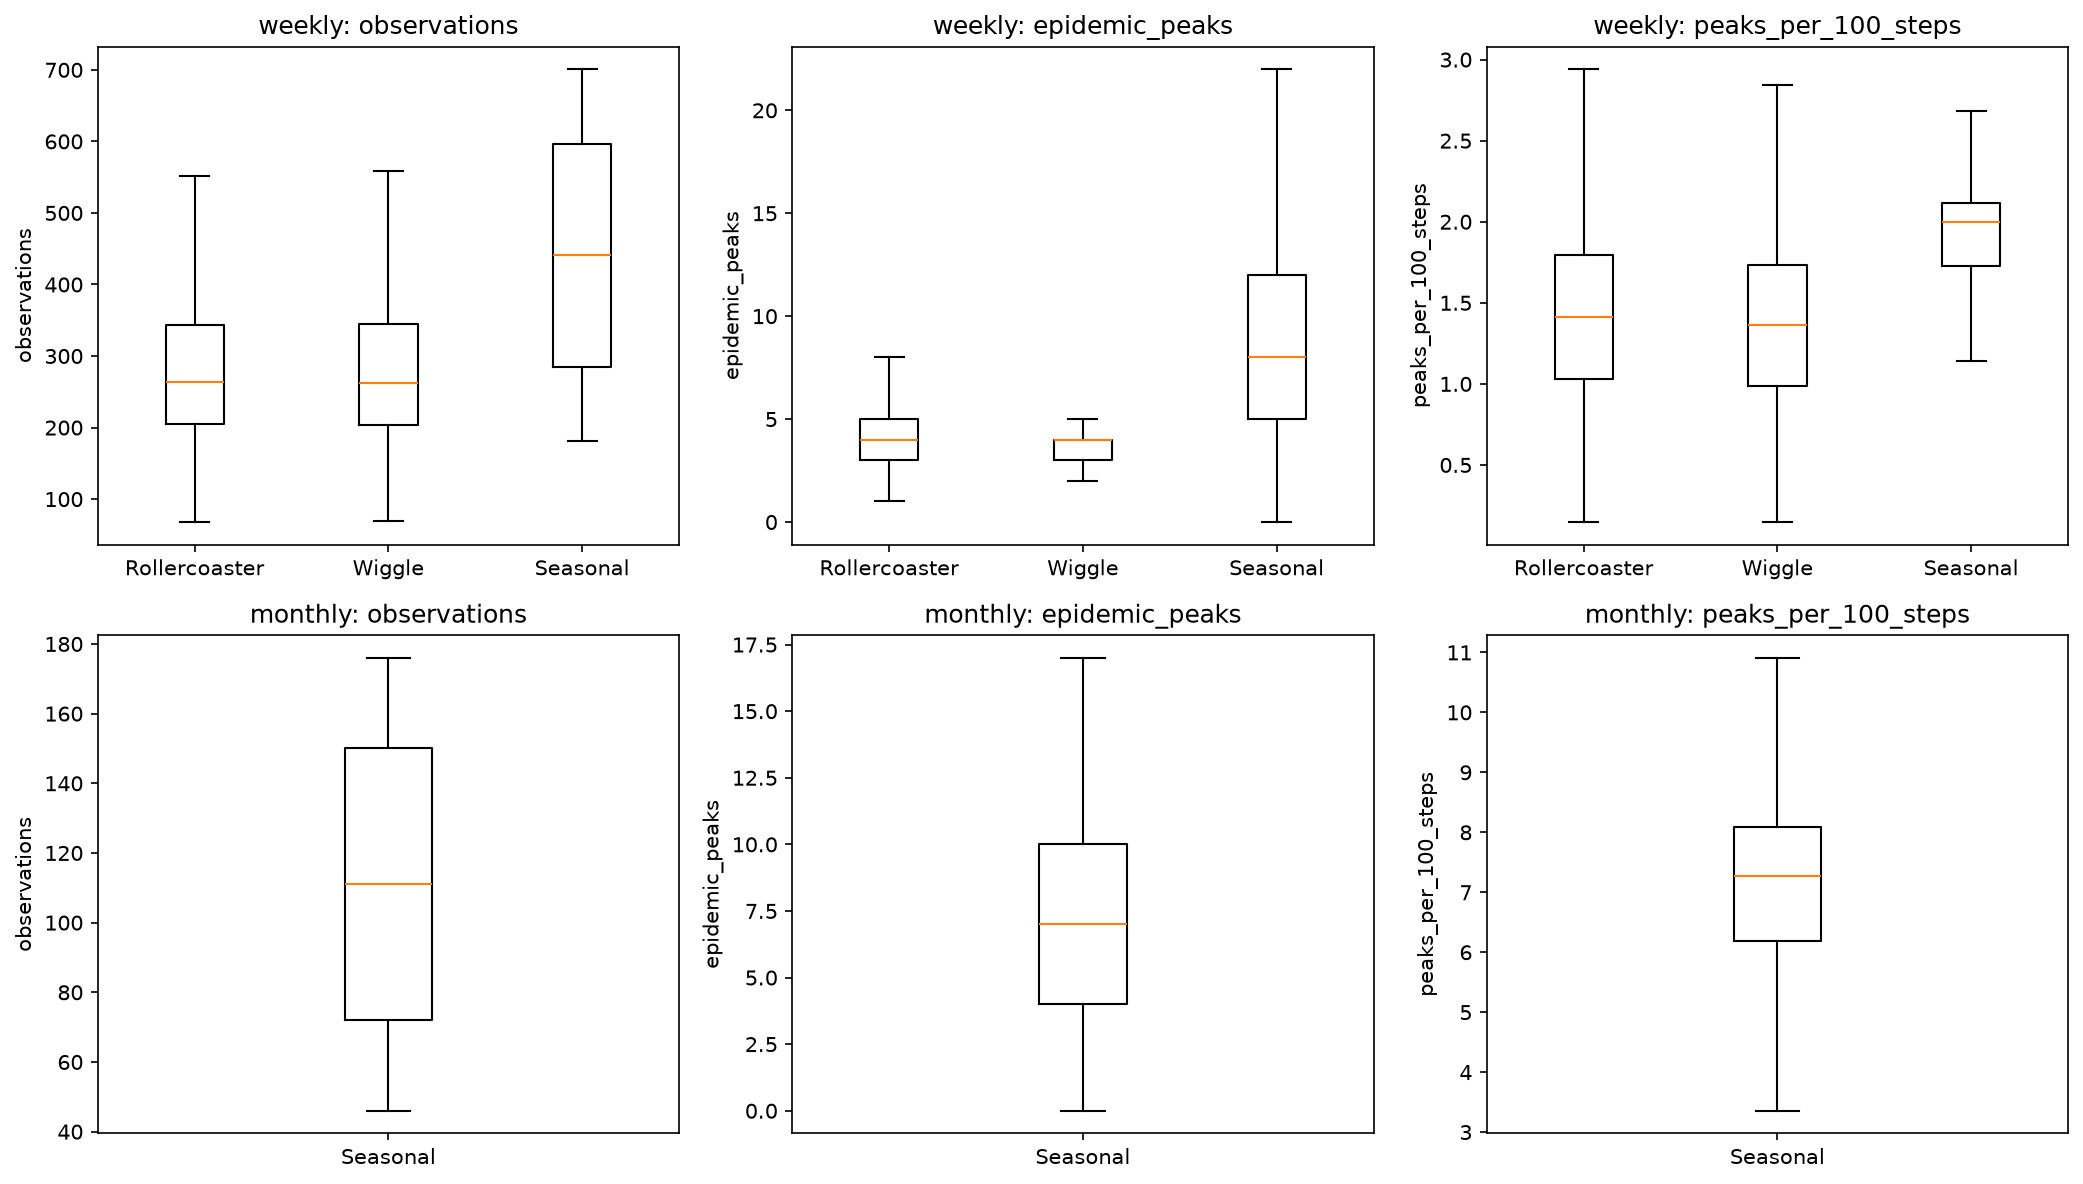

In [3]:
figure('synthetic','01_shapes')
figure('synthetic','02_lengths_and_peaks')

### Scale và phân phối mức biến động
Scale counts/proportion được vẽ riêng. ECDF cho biết tỷ lệ curves có biến động nhỏ hơn hoặc bằng mỗi mức trên trục x.

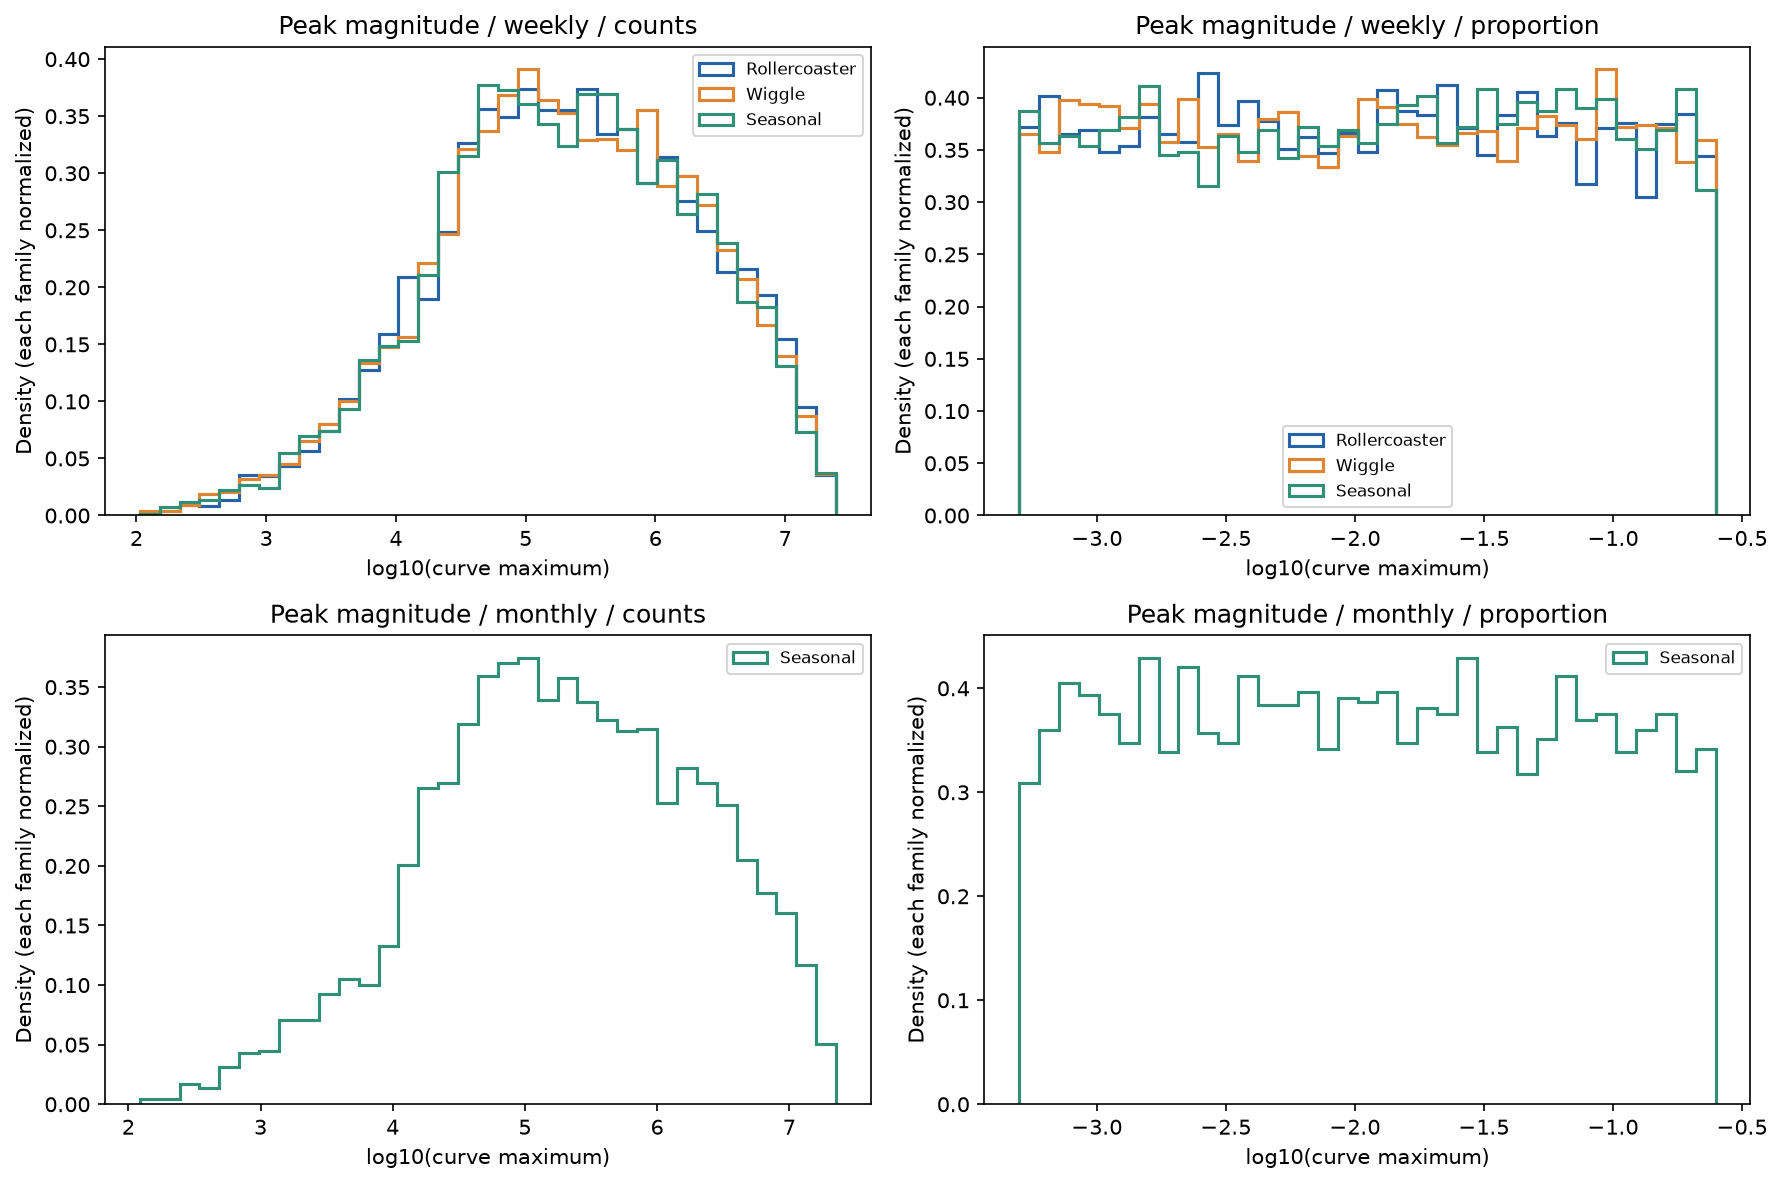

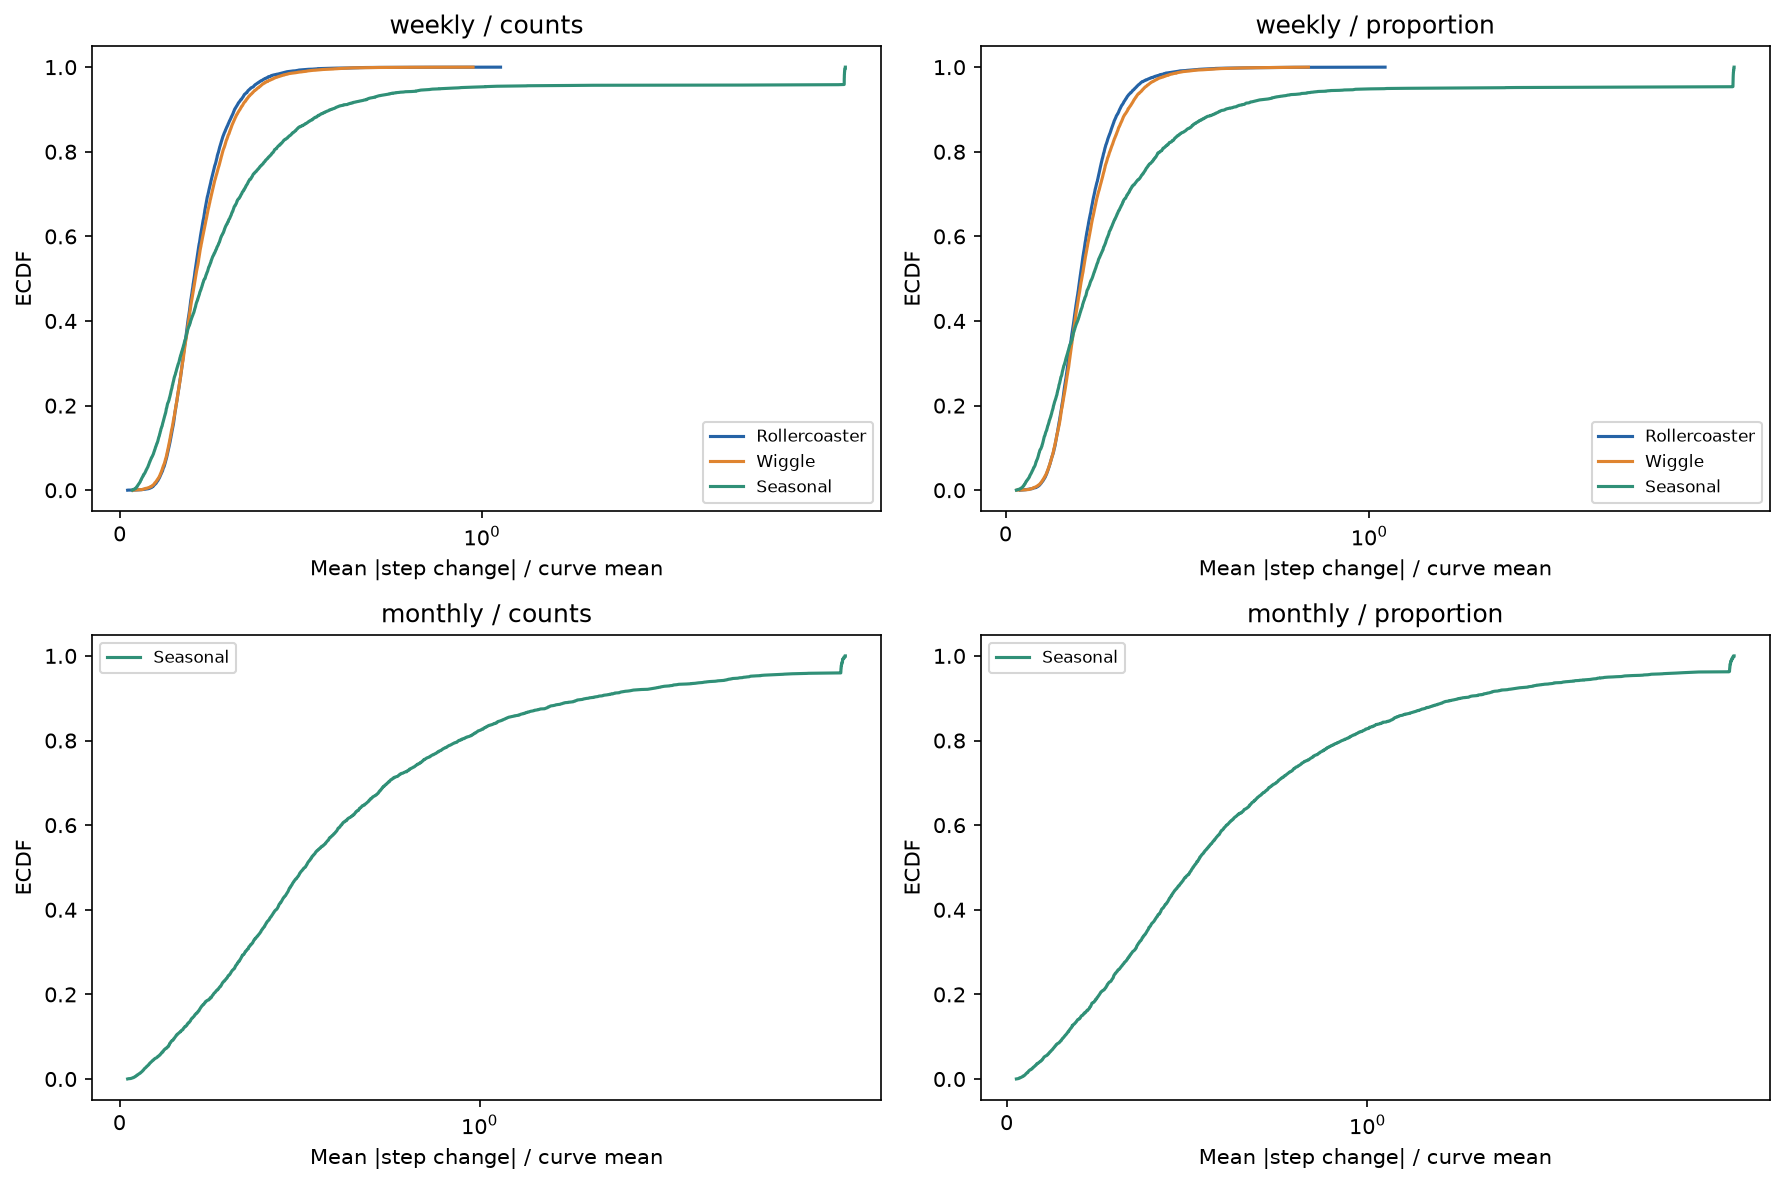

In [4]:
figure('synthetic','03_scale_distributions')
figure('synthetic','04_volatility')

### So sánh cùng cadence/scale và độ nhạy đếm đỉnh

In [5]:
curves = table('synthetic', 'curves')
display(groups.loc[groups.scale.eq('counts') & groups.time_cadence.eq('weekly'), ['curve_type','curves','observations_median','epidemic_peaks_median','mean_absolute_change_over_mean_median']])
display(curves.groupby(['curve_type','scale','time_cadence'])[['peaks_prominence_05','epidemic_peaks','peaks_prominence_20','raw_prominent_peaks','boundary_maximum']].median())

,curve_type,curves,observations_median,epidemic_peaks_median,mean_absolute_change_over_mean_median
0,sir_rollercoaster,9114,263.0,4.0,0.204329
3,sir_rollercoaster_wiggle,9259,262.0,4.0,0.207901
5,seasonal,4390,441.0,8.0,0.234198


peaks_prominence_05  \
curve_type               scale      time_cadence                        
seasonal                 counts     monthly                       7.0   
                                    weekly                        9.0   
                         proportion monthly                       7.0   
                                    weekly                        9.0   
sir_rollercoaster        counts     weekly                        4.0   
                         proportion weekly                        4.0   
sir_rollercoaster_wiggle counts     weekly                        4.0   
                         proportion weekly                        4.0   

                                                  epidemic_peaks  \
curve_type               scale      time_cadence                   
seasonal                 counts     monthly                  7.0   
                                    weekly                   8.0   
                         proportion monthly                  7.0   
                                    weekly                   8.0   
sir_rollercoaster        counts     weekly                   4.0   
                         proportion weekly                   4.0   
sir_rollercoaster_wiggle counts     weekly                   4.0   
                         proportion weekly                   4.0   

                                                  peaks_prominence_20  \
curve_type               scale      time_cadence                        
seasonal                 counts     monthly                       6.0   
                                    weekly                        7.0   
                         proportion monthly                       6.0   
                                    weekly                        7.0   
sir_rollercoaster        counts     weekly                        3.0   
                         proportion weekly                        3.0   
sir_rollercoaster_wiggle counts     weekly                        3.0   
                         proportion weekly                        3.0   

                                                  raw_prominent_peaks  \
curve_type               scale      time_cadence                        
seasonal                 counts     monthly                       7.0   
                                    weekly                       10.0   
                         proportion monthly                       7.0   
                                    weekly                       10.0   
sir_rollercoaster        counts     weekly                        4.0   
                         proportion weekly                        4.0   
sir_rollercoaster_wiggle counts     weekly                        4.0   
                         proportion weekly                        4.0   

                                                  boundary_maximum  
curve_type               scale      time_cadence                    
seasonal                 counts     monthly                    0.0  
                                    weekly                     0.0  
                         proportion monthly                    0.0  
                                    weekly                     0.0  
sir_rollercoaster        counts     weekly                     0.0  
                         proportion weekly                     0.0  
sir_rollercoaster_wiggle counts     weekly                     0.0  
                         proportion weekly                     0.0

## 2. Real-World Dataset Exploration

Giữ nguyên raw weekly counts, bao gồm zero và số âm do revisions. Dùng lịch giao nhau của 50 bang để so sánh công bằng; phần Arizona dài hơn vẫn có trong `final_all_records.csv`.

Census regions và population estimate 2019 được lưu trong repo. Regional rate = tổng cases / tổng population ×100.000, không phải trung bình không trọng số của các bang.

In [6]:
display(pd.Series(summary['real_world']))
display(table('real_world','case_distribution'))
display(table('real_world','region_summary'))

states                                                                       50
source_records                                                             7267
common_records                                                             7250
common_start                                                         2020-01-25
common_end                                                           2022-10-29
negative_values                                                               8
zeros                                                                       324
sharp_events                                                                591
sustained_low_high_periods                                                  480
historical_pairs                                                         478800
origin_week_pairs                                                          5600
latest_revision               {'pairs': 5600, 'states': 50, 'target_weeks': ...
balanced_target_pairs                   

,group,weeks,states,zeros,negatives,value_mean,value_median,value_p05,value_p95,value_min,value_max,cases_per_100k_mean,cases_per_100k_median,cases_per_100k_p05,cases_per_100k_p95,cases_per_100k_min,cases_per_100k_max,peak_date
0,all_state_weeks,7250,50,324,8,13268.061931,4772.0,3.0,50118.85,-25117.0,852280.0,204.826385,121.030058,0.067495,638.017528,-346.824455,3402.334049,2022-01-15


,region,states,population_2019,mean_weekly_cases,mean_cases_per_100k,median_cases_per_100k,peak_cases_per_100k,peak_date
0,Midwest,12,68329004,137205.620690,200.801435,136.019837,1515.173556,2022-01-15
1,Northeast,9,55982803,114293.406897,204.158064,154.965445,2163.553690,2022-01-08
2,South,16,124874699,258470.117241,206.983576,120.853945,1652.633413,2022-01-15
3,West,13,78347268,153433.951724,195.838292,117.872649,1847.225866,2022-01-22


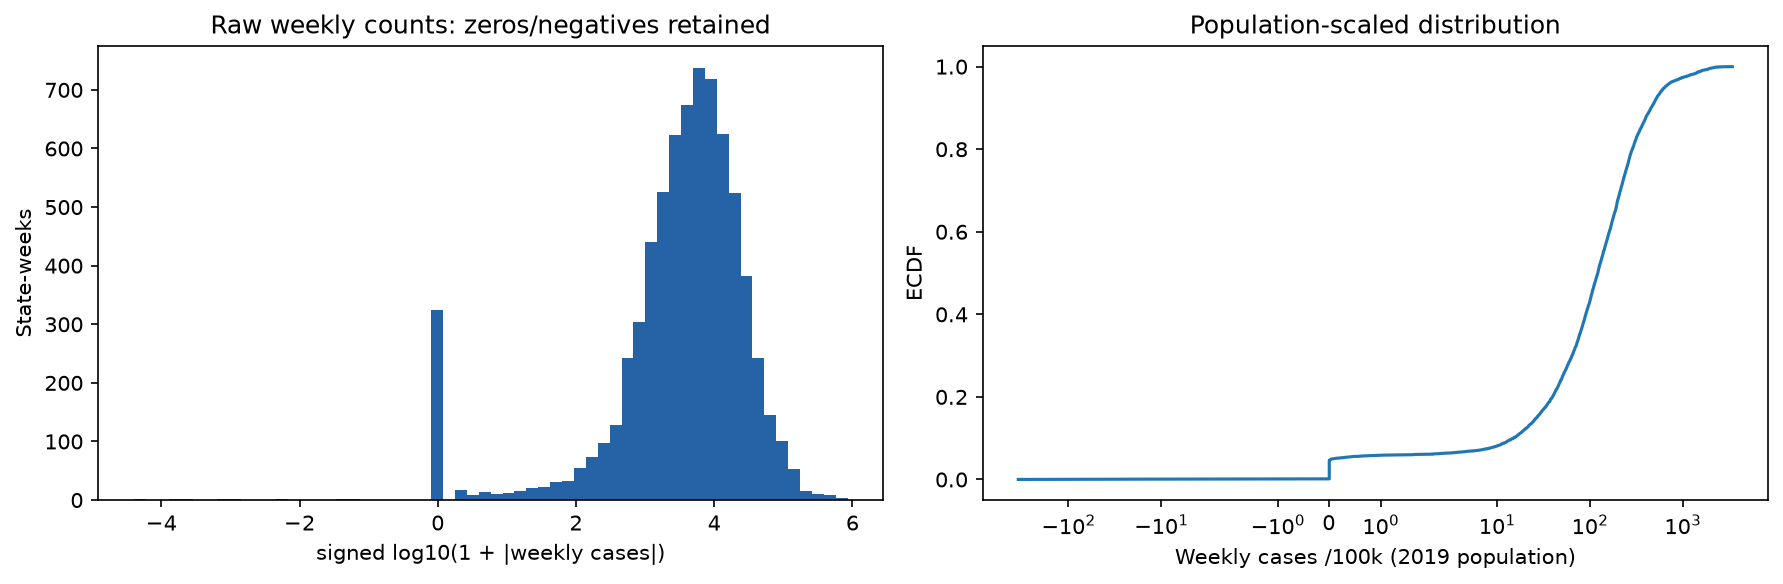

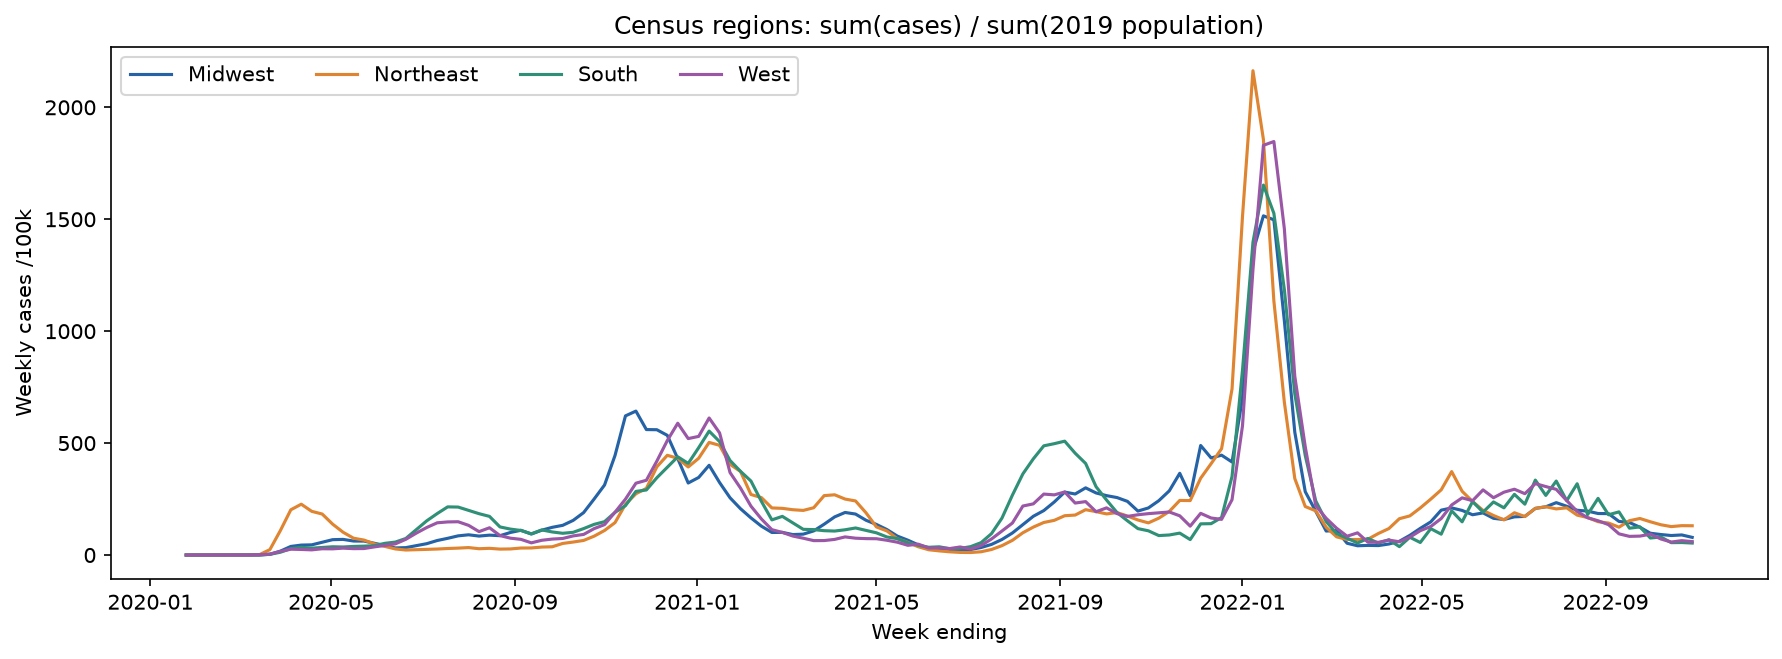

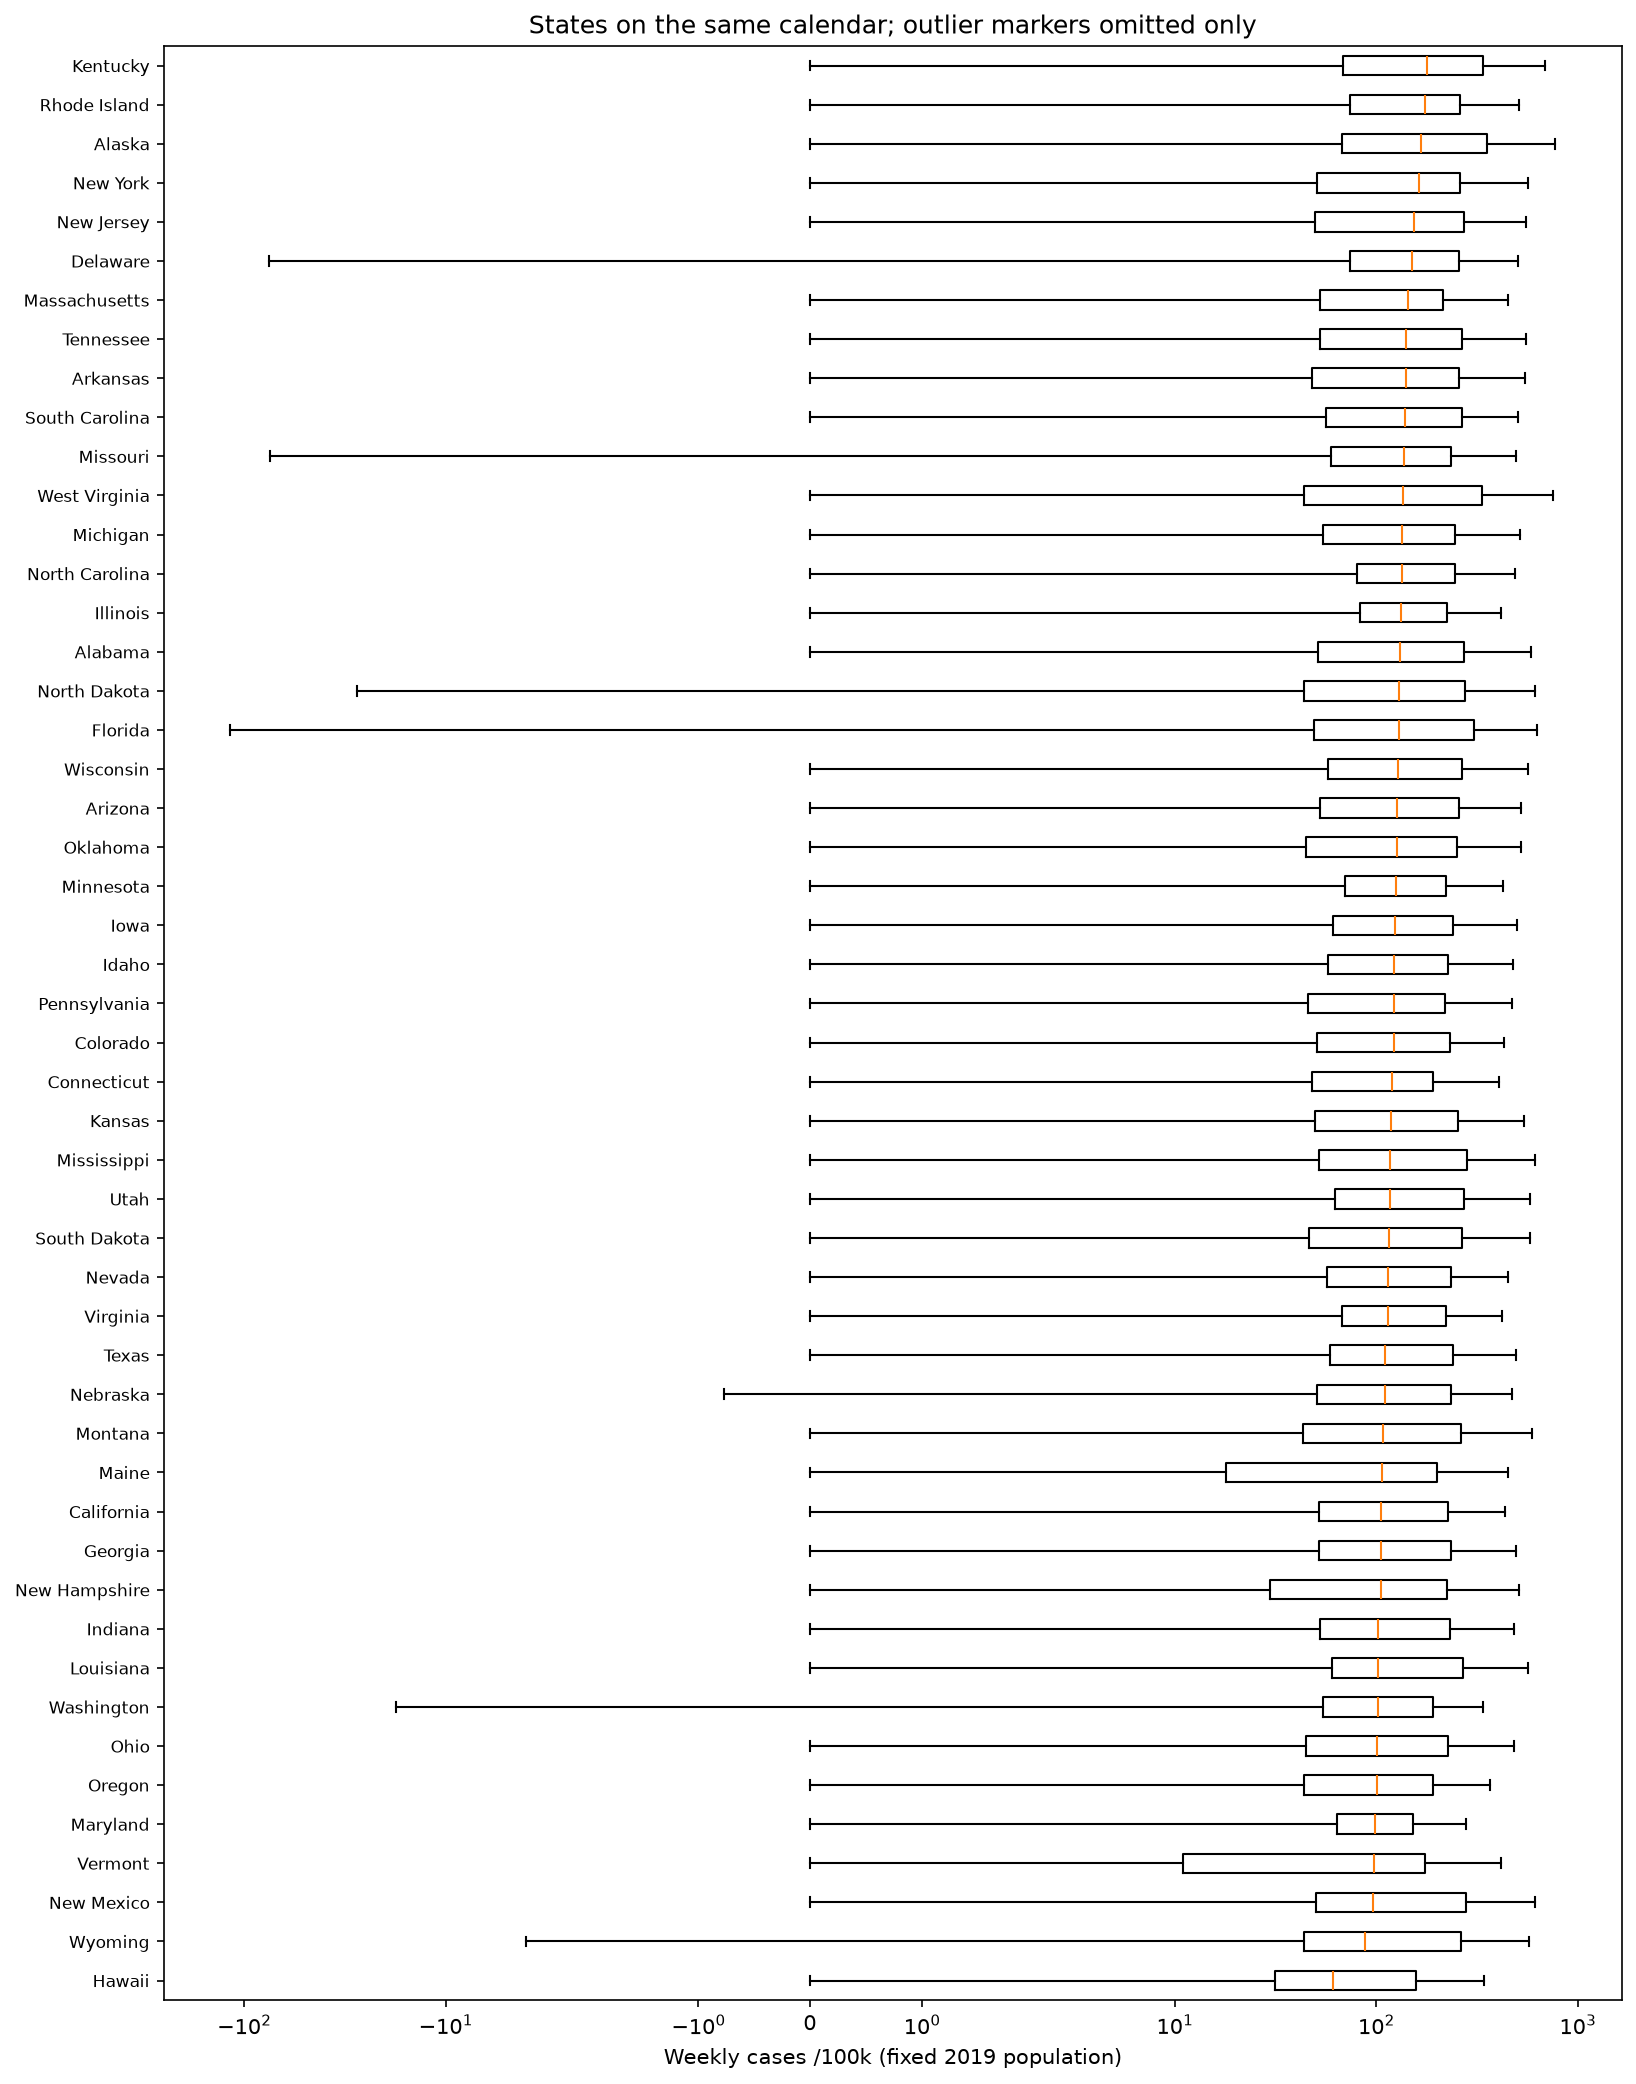

In [7]:
figure('real_world','01_case_distribution')
figure('real_world','03_regions')
figure('real_world','04_state_distributions')

### Những đợt tăng/giảm mạnh

Quy tắc đặt trước: hai tuần liên tiếp; |delta| ≥1.000 cases và |delta/previous| ≥50%; previous >0, current ≥0. Zero→positive được đánh dấu riêng. Những bước nhảy do backlog/reporting không nhất thiết phản ánh thay đổi sinh học.

,series,target_end_date,previous_value,value,change,relative_change
0,California,2022-01-15,541840.0,852280.0,310440.0,0.572937
1,California,2022-01-08,233453.0,541840.0,308387.0,1.320981
2,New York,2022-01-01,167569.0,415674.0,248105.0,1.480614
3,Texas,2022-01-08,142538.0,371815.0,229277.0,1.608532
4,Florida,2022-01-01,124865.0,302179.0,177314.0,1.420046
5,California,2022-01-01,89712.0,233453.0,143741.0,1.602249
6,California,2022-02-19,204021.0,96146.0,-107875.0,-0.528745
7,Illinois,2022-01-08,128254.0,232906.0,104652.0,0.815975
8,Florida,2022-08-13,22201.0,124717.0,102516.0,4.617630
9,Florida,2022-07-16,24321.0,121748.0,97427.0,4.005880


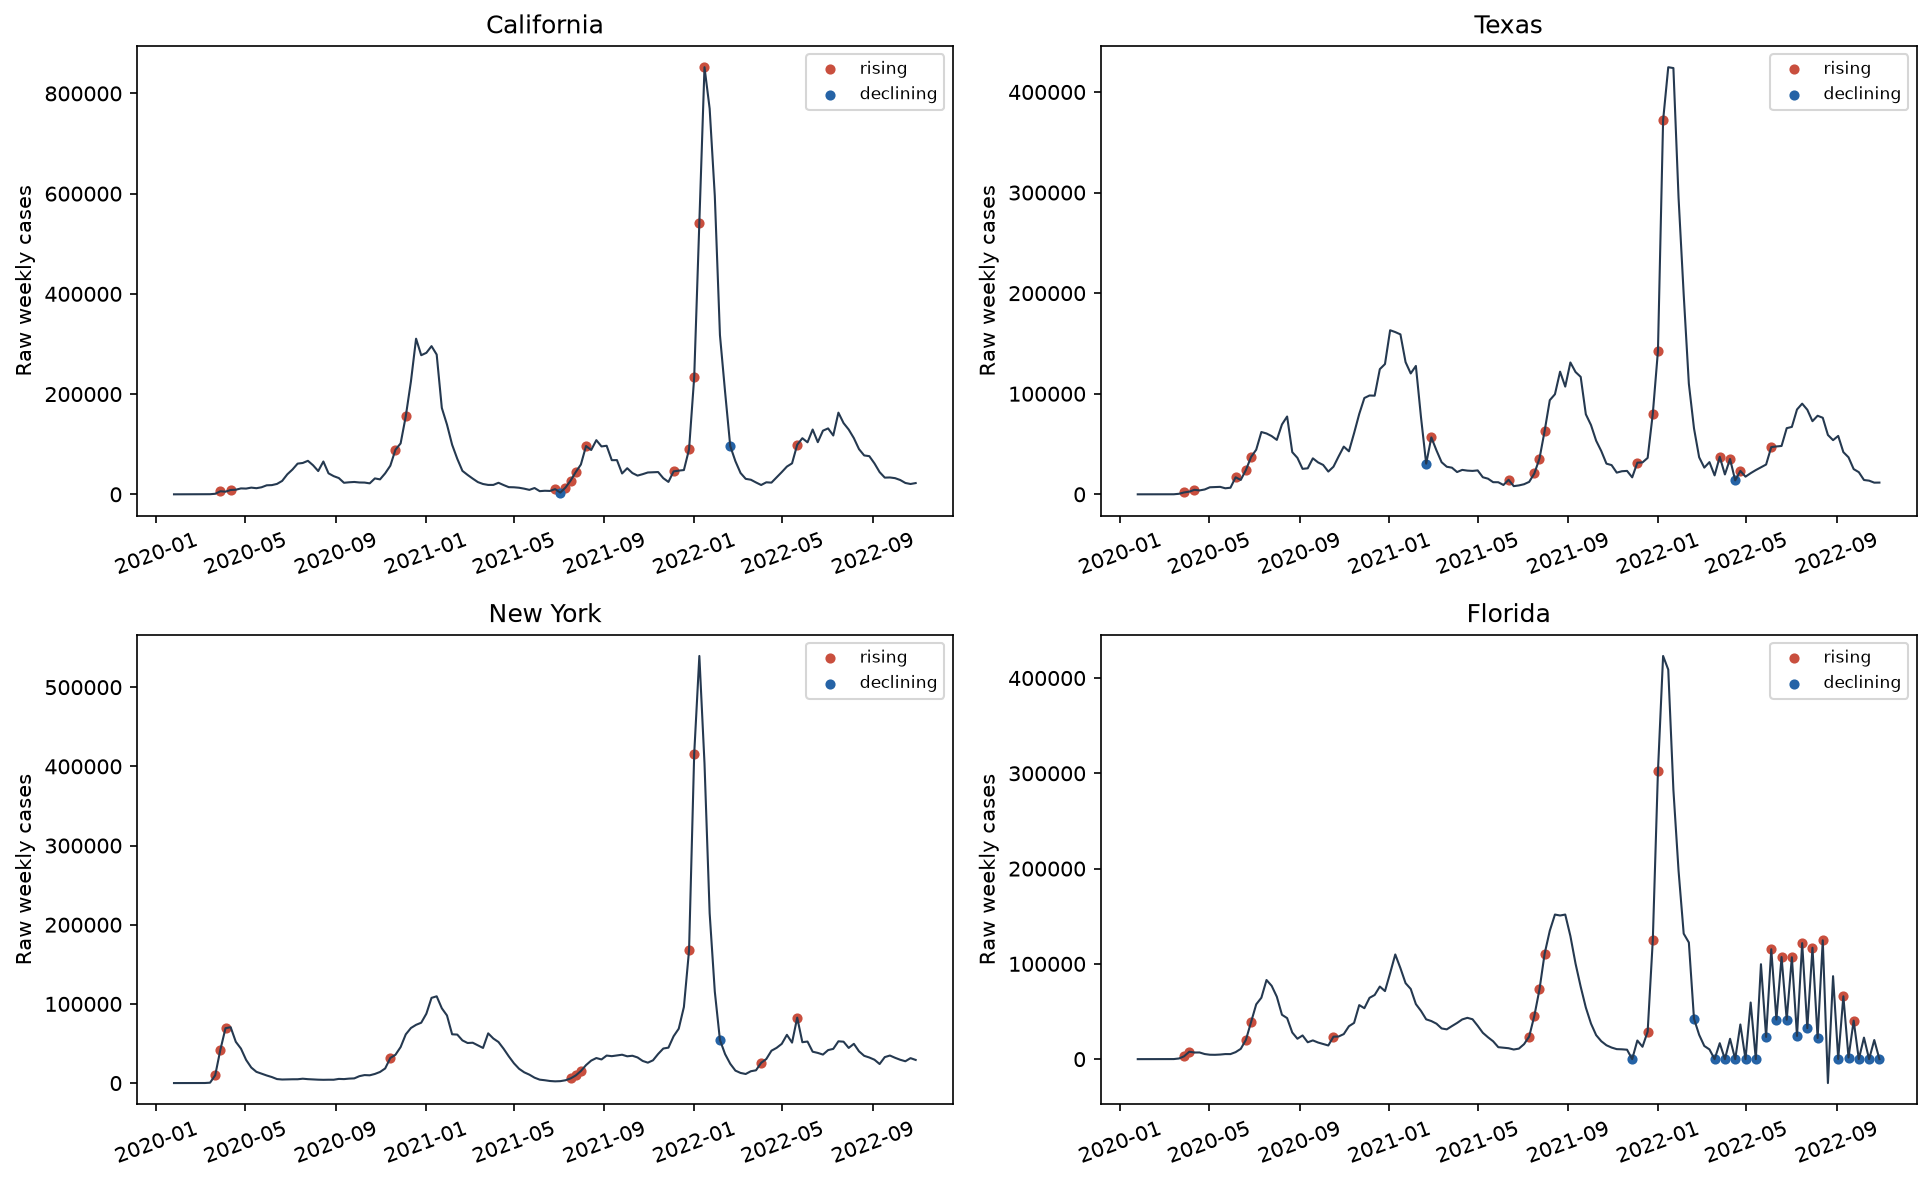

In [8]:
display(table('real_world','sharp_changes')[['series','target_end_date','previous_value','value','change','relative_change']].head(15))
figure('real_world','02_sharp_changes')

### Những khoảng rất thấp hoặc rất cao

Raw counts: low 0–100/tuần, high ≥10.000/tuần. Rate: low 0–1/100.000/tuần, high ≥100/100.000/tuần. Negative revisions không được gán là low. Khoảng kéo dài ≥3 tuần được đánh dấu sustained; CSV vẫn giữ cả những khoảng ngắn hơn. Các ngưỡng mô tả này không phải ngưỡng cảnh báo lâm sàng.

,series,region,unit,level,start,end,weeks,sustained,min_value,median_value,max_value
101,Florida,South,value,high,2020-06-13,2021-11-13,75,True,10095.000000,38019.000000,151764.000000
558,Texas,South,value,high,2021-07-03,2022-10-29,70,True,10030.000000,42465.000000,424635.000000
50,California,West,value,high,2021-07-10,2022-10-29,69,True,13333.000000,59479.000000,852280.000000
425,New York,Northeast,value,high,2021-07-31,2022-10-29,66,True,11464.000000,35316.500000,539437.000000
525,South Carolina,South,cases_per_100k,high,2020-06-20,2021-05-01,46,True,103.520996,165.517059,725.734620
587,Vermont,Northeast,cases_per_100k,high,2021-08-14,2022-06-18,45,True,115.386649,241.029890,1918.944084
551,Tennessee,South,cases_per_100k,high,2020-07-04,2021-04-24,43,True,108.461140,191.780148,960.936125
23,Alaska,West,cases_per_100k,high,2022-01-01,2022-09-24,39,True,103.479622,297.315955,2330.820387
580,Vermont,Northeast,value,low,2020-04-18,2020-10-17,27,True,13.000000,42.000000,92.000000
17,Alaska,West,value,low,2020-01-25,2020-05-30,19,True,0.000000,15.000000,89.000000


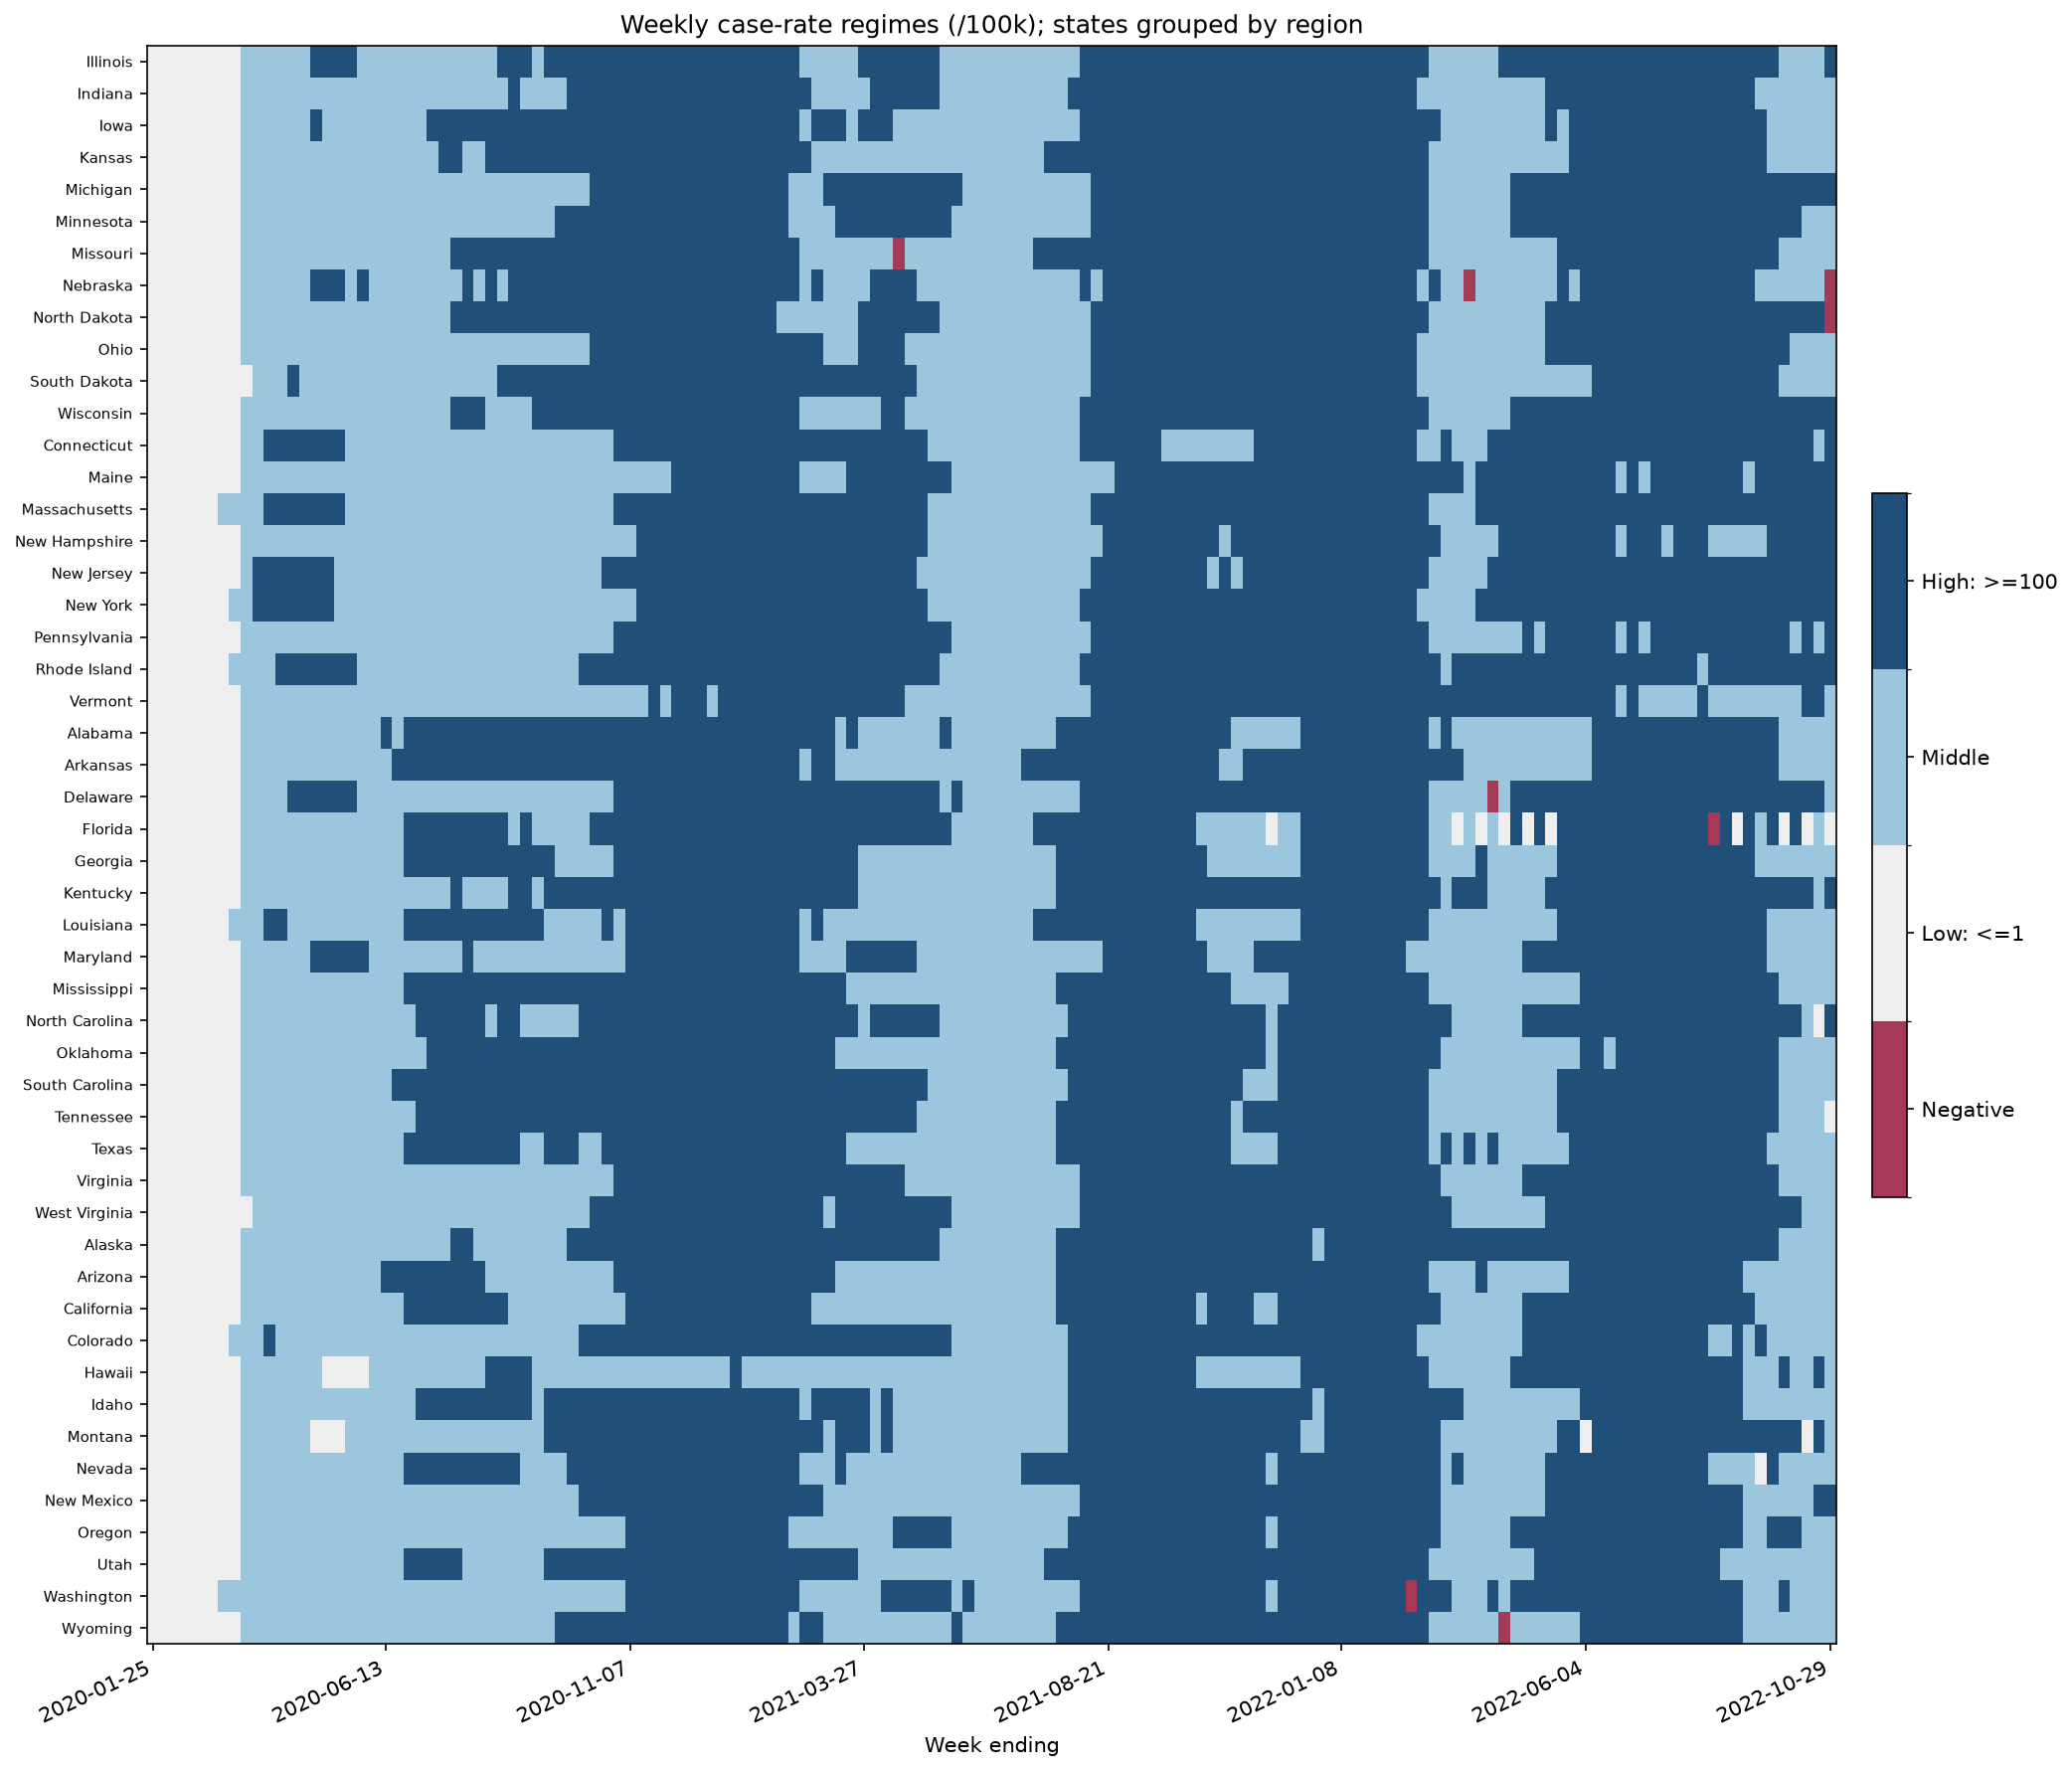

In [9]:
runs = table('real_world','low_high_periods')
display(runs.loc[runs.sustained].sort_values('weeks',ascending=False).groupby(['unit','level'],sort=False).head(4))
figure('real_world','05_low_high_periods')

### Historical as-of so với final truth

Ghép chính xác state/target date. `revision = final − as_of`: dương nghĩa là final cao hơn.

- **Lag 0:** mỗi state/target một lần, thể hiện chênh lệch ở origin.
- **Balanced lag 0–12:** chỉ dùng state/targets có đủ 13 vintages, để đường lag phản ánh cùng một cohort.
- Symmetric relative difference = 2|final−asof|/(|final|+|asof|); cả hai zero →0; range 0–200%.

As-of được dựng từ JHU county snapshots; final từ LANL state_truths. Chênh lệch có thể gồm revisions lẫn khác biệt upstream/aggregation. Nhãn origin là Saturday; snapshot cutoff Sunday và issuance Monday theo nguồn, không giả định dữ liệu Sunday đã có vào Saturday.

In [10]:
display(pd.Series(summary['real_world']['latest_revision']))
display(table('real_world','revision_balanced_lag'))
display(table('real_world','revision_by_state').sort_values('absolute_revision_mean',ascending=False).head(10))

pairs                               5600.000000
states                                50.000000
target_weeks                         112.000000
signed_revision_mean                 133.690893
absolute_revision_mean               433.943750
absolute_revision_median               0.000000
absolute_revision_p90                311.000000
symmetric_relative_revision_mean       0.023180
changed_fraction                       0.187679
upward_fraction                        0.124464
downward_fraction                      0.063214
dtype: float64

,lag_weeks,pairs,states,target_weeks,signed_revision_mean,absolute_revision_mean,absolute_revision_median,absolute_revision_p90,symmetric_relative_revision_mean,changed_fraction,upward_fraction,downward_fraction
0,0,5000,50,100,140.0076,447.7772,0.0,358.2,0.023468,0.1962,0.1296,0.0666
1,1,5000,50,100,136.7066,378.9350,0.0,299.2,0.021055,0.1878,0.1252,0.0626
2,2,5000,50,100,119.8462,337.0042,0.0,226.0,0.016395,0.1822,0.1160,0.0662
3,3,5000,50,100,99.5184,317.7112,0.0,182.0,0.015165,0.1768,0.1096,0.0672
4,4,5000,50,100,85.8754,303.9658,0.0,161.1,0.014174,0.1714,0.1046,0.0668
5,5,5000,50,100,101.3014,285.5754,0.0,134.3,0.013457,0.1660,0.1012,0.0648
6,6,5000,50,100,92.9950,276.3522,0.0,121.0,0.012859,0.1614,0.0968,0.0646
7,7,5000,50,100,91.6862,265.6298,0.0,99.4,0.012441,0.1570,0.0930,0.0640
8,8,5000,50,100,77.5020,251.3276,0.0,83.1,0.012059,0.1524,0.0896,0.0628
9,9,5000,50,100,63.2074,232.8418,0.0,72.0,0.011443,0.1482,0.0864,0.0618


,series,pairs,states,target_weeks,signed_revision_mean,absolute_revision_mean,absolute_revision_median,absolute_revision_p90,symmetric_relative_revision_mean,changed_fraction,upward_fraction,downward_fraction
42,Texas,112,1,112,640.276786,4688.991071,491.0,10516.9,0.071624,0.919643,0.437500,0.482143
41,Tennessee,112,1,112,1056.455357,4210.598214,1227.5,8645.9,0.224298,1.000000,0.633929,0.366071
4,California,112,1,112,1724.232143,4095.035714,1594.5,13606.1,0.057105,1.000000,0.589286,0.410714
5,Colorado,112,1,112,-16.669643,3323.008929,1233.5,6424.8,0.230980,0.946429,0.401786,0.544643
19,Maryland,112,1,112,223.794643,993.848214,0.0,0.0,0.060420,0.098214,0.080357,0.017857
24,Missouri,112,1,112,840.821429,840.821429,0.0,3243.0,0.102534,0.401786,0.401786,0.000000
17,Louisiana,112,1,112,714.339286,714.339286,0.0,747.8,0.046352,0.294643,0.294643,0.000000
29,New Jersey,112,1,112,561.991071,561.991071,0.0,1789.3,0.033830,0.196429,0.196429,0.000000
37,Pennsylvania,112,1,112,43.660714,387.821429,52.5,794.9,0.022790,0.589286,0.473214,0.116071
9,Georgia,112,1,112,296.535714,296.535714,0.0,0.0,0.010728,0.008929,0.008929,0.000000


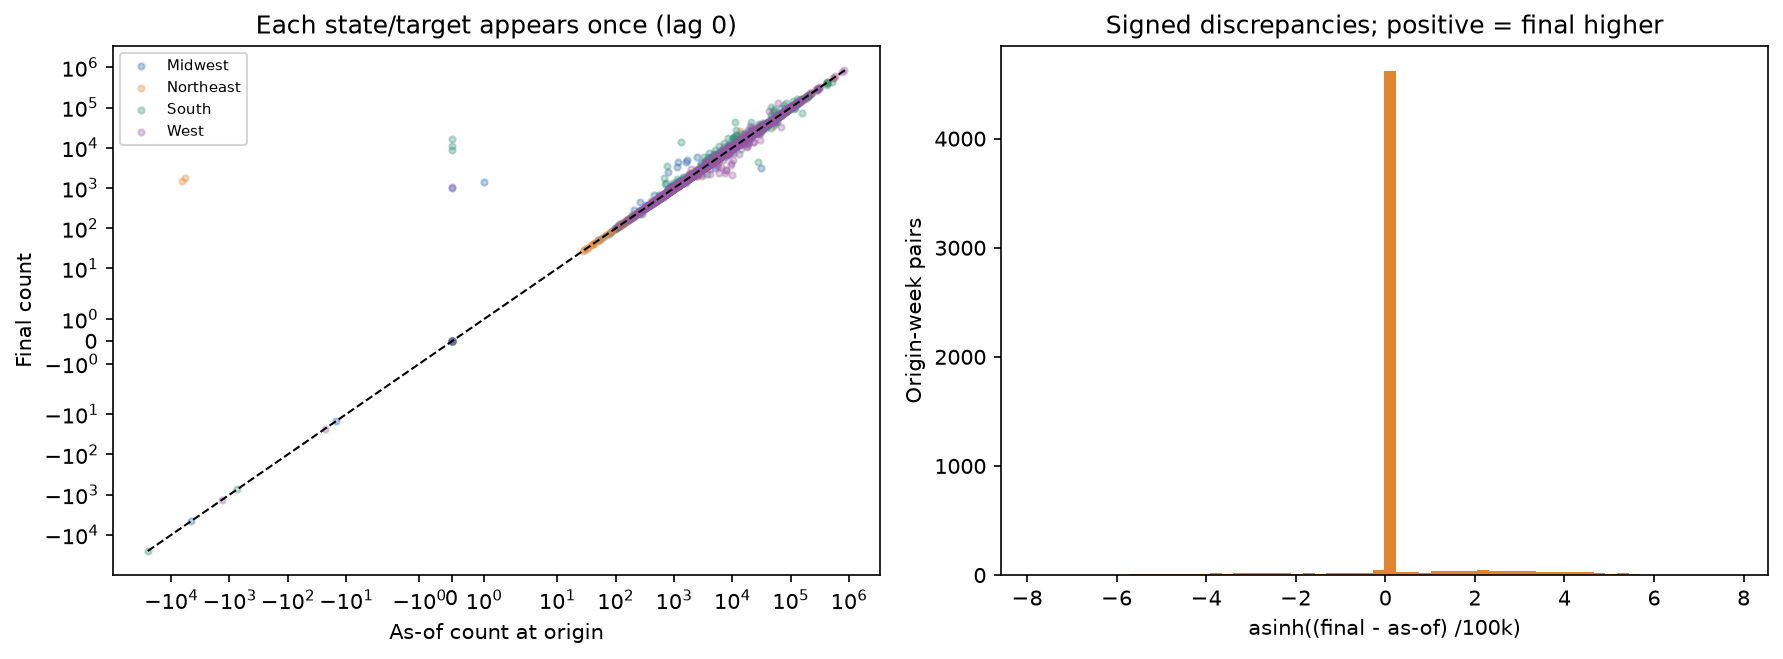

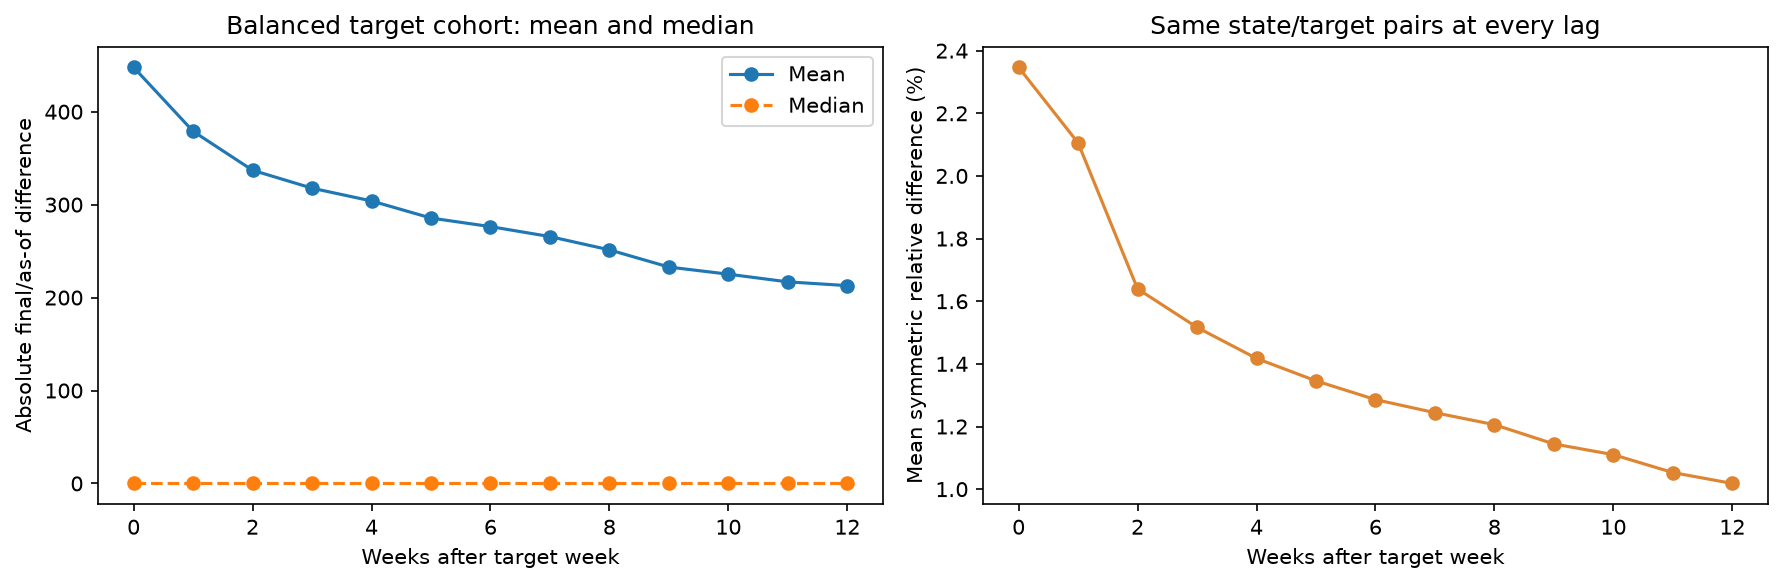

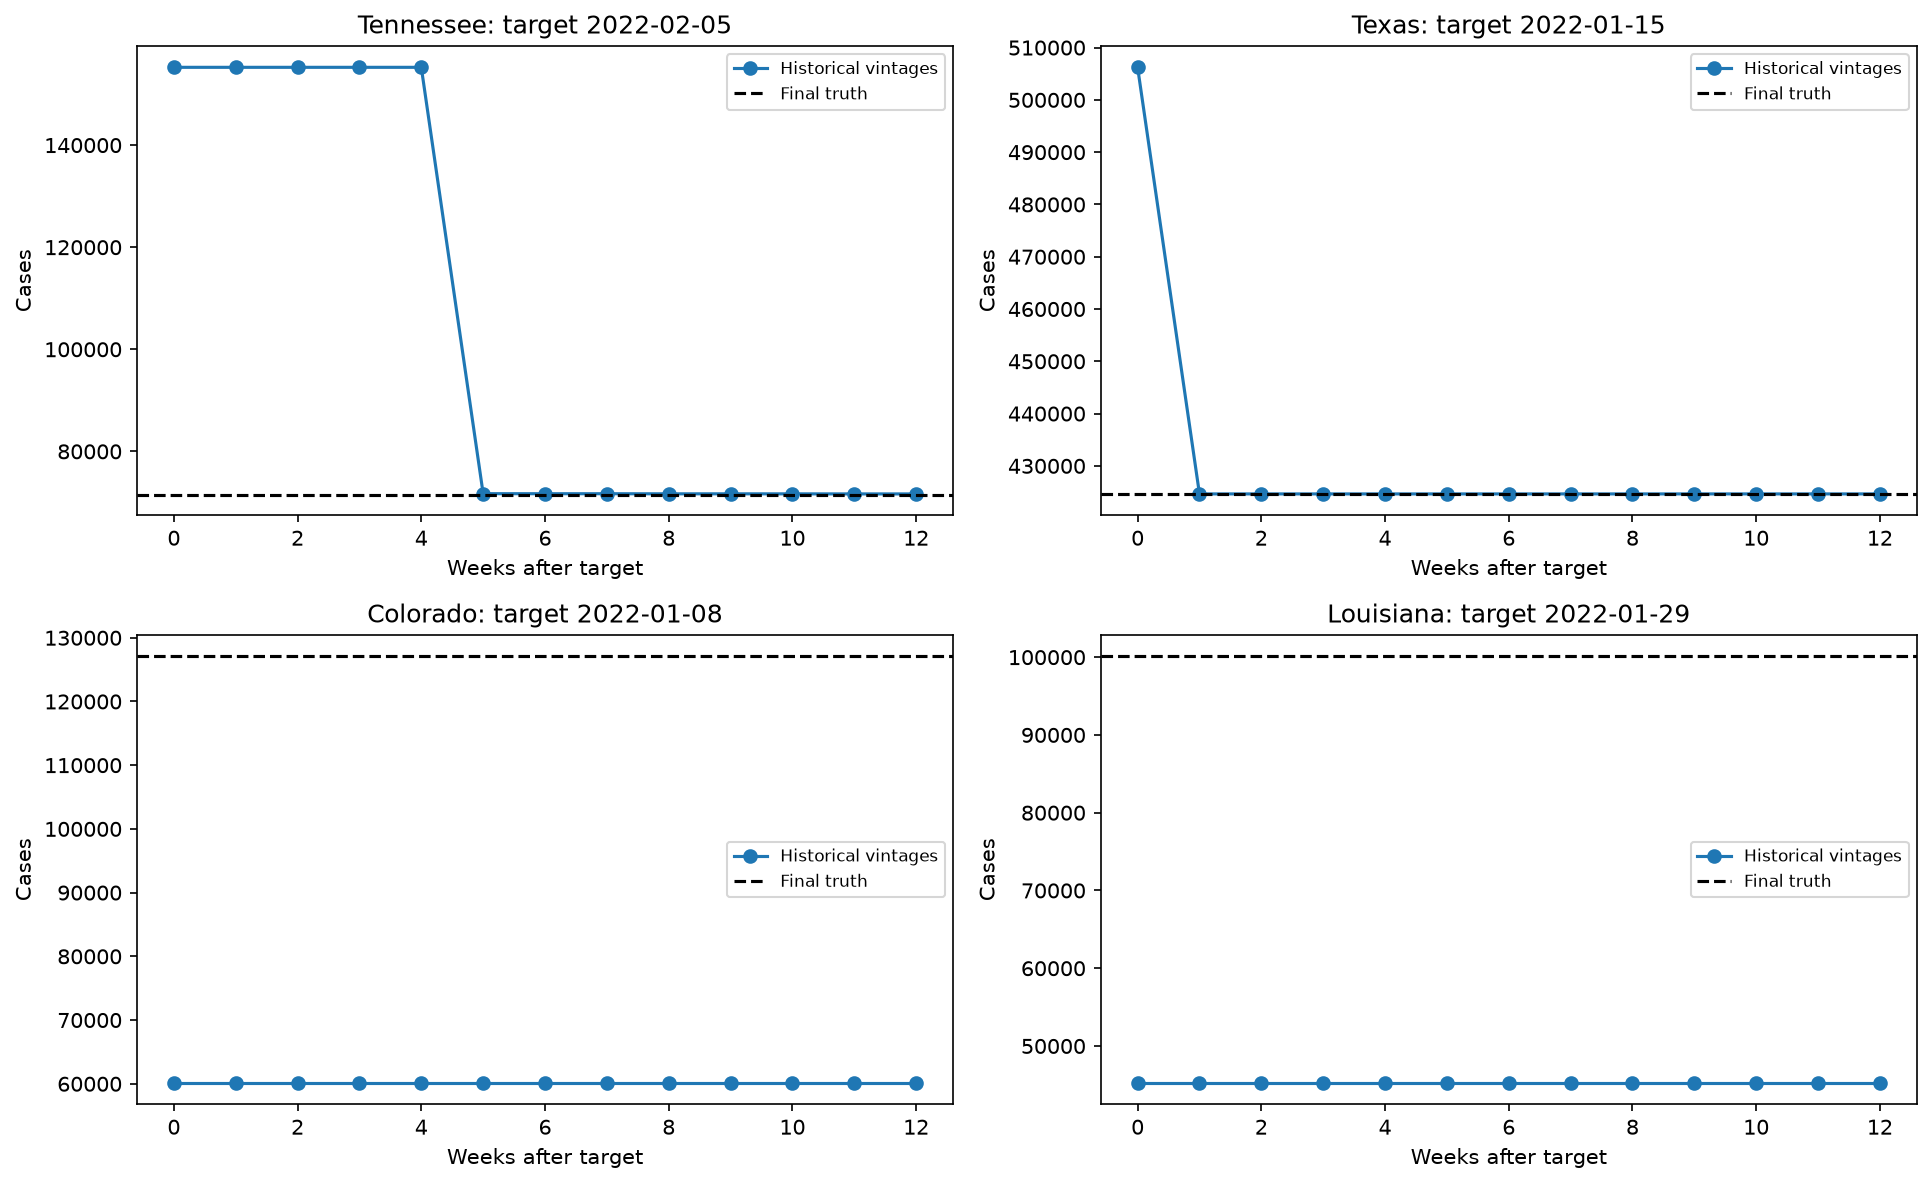

In [11]:
figure('real_world','06_asof_vs_final')
figure('real_world','07_revision_lag')
figure('real_world','08_revision_examples')

Revision examples chọn hậu nghiệm các chênh lệch tuyệt đối lớn nhất tại bốn bang khác nhau, để kiểm tra trường hợp bất thường; không đại diện toàn bộ tập dữ liệu.

## Nhận xét và các artifact

Báo cáo dưới đây được sinh từ dữ liệu, kèm cùng các hình trên. CSV chi tiết ở `outputs/dataset_exploration/{synthetic,real_world}`; `metadata.json` lưu checksum inputs/code và phiên bản phần mềm. SVG dùng để xuất hình.

In [12]:
for area in ['synthetic','real_world']:
    text = (OUT / area / 'report.md').read_text()
    display(Markdown(text.split('![')[0]))

# Synthetic Dataset Exploration

54,081 accepted curves, 15,510,156 observations; 55161 attempts. Full CSV scanned, no statistical subsampling.

| curve_type | scale | time_cadence | curves | observations_median | epidemic_peaks_median | mean_absolute_change_over_mean_median |
| --- | --- | --- | --- | --- | --- | --- |
| sir_rollercoaster | counts | weekly | 9,114.000 | 263.000 | 4.000 | 0.204 |
| sir_rollercoaster | proportion | weekly | 9,273.000 | 265.000 | 4.000 | 0.203 |
| sir_rollercoaster_wiggle | proportion | weekly | 9,128.000 | 263.000 | 4.000 | 0.209 |
| sir_rollercoaster_wiggle | counts | weekly | 9,259.000 | 262.000 | 4.000 | 0.208 |
| seasonal | proportion | monthly | 4,288.000 | 111.000 | 7.000 | 0.516 |
| seasonal | counts | weekly | 4,390.000 | 441.000 | 8.000 | 0.234 |
| seasonal | proportion | weekly | 4,322.000 | 441.000 | 8.000 | 0.237 |
| seasonal | counts | monthly | 4,307.000 | 111.000 | 7.000 | 0.514 |

## Định nghĩa và cách đọc

- Epidemic peak: median-3 smoothing, prominence ≥10% curve range, distance ≥4 original steps. Endpoints không được tính; cột boundary_maximum ghi riêng. Sensitivity 5%/20% có trong curves.csv.
- Peak counts là số đỉnh phát hiện trên observations, không phải số SIR components; waves có thể chồng lấn và bị ảnh hưởng bởi noise/rounding.
- Volatility chính: mean(abs(diff(values)))/mean(values). Không phụ thuộc nhân scale; so sánh trong cùng cadence/scale. CV và SD(diff)/mean cũng được xuất.
- Counts và proportion được giữ riêng; weekly và monthly không phải cùng đơn vị thời gian. Peak density /100 steps không được gộp qua cadence.
- Độ dài khác nhau ảnh hưởng số đỉnh và số embedding windows. Đây là mô tả các họ dữ liệu, không phải paired causal effect của wiggle.

## Khác biệt theo cùng đơn vị weekly/counts

- Rollercoaster: median length 263 steps; detected peaks 4.0; relative step volatility 0.2043.
- Wiggle: median length 262 steps; detected peaks 4.0; relative step volatility 0.2079.
- Seasonal: median length 441 steps; detected peaks 8.0; relative step volatility 0.2342.

Embedding windows k=5/h=4: giữ bridge 15,023,012; bỏ bridge 14,968,931. Đây là số windows, không phải số curves.



# Real-World Dataset Exploration

50 bang; 7,267 raw final records. So sánh khu vực dùng lịch chung 2020-01-25–2022-10-29 (7,250 state-weeks), không trộn phần Arizona dài hơn.

Raw common data: 324 zeros, 8 negative revisions. Không floor/impute/drop các giá trị này trong thống kê.

## Phân phối và khác biệt khu vực

Weekly cases/state: median 4,772, mean 13,268.06, p95 50,118.85, max 852,280. Mean cao hơn median cho thấy đuôi phải dài; raw values có cả revisions âm.

| region | states | population_2019 | mean_weekly_cases | mean_cases_per_100k | median_cases_per_100k | peak_cases_per_100k | peak_date |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Midwest | 12.000 | 68,329,004.000 | 137,205.621 | 200.801 | 136.020 | 1,515.174 | 2022-01-15 |
| Northeast | 9.000 | 55,982,803.000 | 114,293.407 | 204.158 | 154.965 | 2,163.554 | 2022-01-08 |
| South | 16.000 | 124,874,699.000 | 258,470.117 | 206.984 | 120.854 | 1,652.633 | 2022-01-15 |
| West | 13.000 | 78,347,268.000 | 153,433.952 | 195.838 | 117.873 | 1,847.226 | 2022-01-22 |

Rates dùng population 2019 cố định từ state_census nguồn; không phải annual population-adjusted risk. Region rate = sum(cases)/sum(population), không phải mean các state rates.

## Những tuần tăng/giảm mạnh

591 events thỏa đồng thời |weekly change| ≥1.000 và |relative change| ≥50%, previous>0/current>=0. Zero→positive được đánh dấu riêng; không chia cho zero hoặc tự thêm epsilon.

| series | target_end_date | previous_value | value | change | relative_change |
| --- | --- | --- | --- | --- | --- |
| California | 2022-01-15 00:00:00 | 541,840.000 | 852,280.000 | 310,440.000 | 0.573 |
| California | 2022-01-08 00:00:00 | 233,453.000 | 541,840.000 | 308,387.000 | 1.321 |
| New York | 2022-01-01 00:00:00 | 167,569.000 | 415,674.000 | 248,105.000 | 1.481 |
| Texas | 2022-01-08 00:00:00 | 142,538.000 | 371,815.000 | 229,277.000 | 1.609 |
| Florida | 2022-01-01 00:00:00 | 124,865.000 | 302,179.000 | 177,314.000 | 1.420 |
| California | 2022-01-01 00:00:00 | 89,712.000 | 233,453.000 | 143,741.000 | 1.602 |
| California | 2022-02-19 00:00:00 | 204,021.000 | 96,146.000 | -107,875.000 | -0.529 |
| Illinois | 2022-01-08 00:00:00 | 128,254.000 | 232,906.000 | 104,652.000 | 0.816 |
| Florida | 2022-08-13 00:00:00 | 22,201.000 | 124,717.000 | 102,516.000 | 4.618 |
| Florida | 2022-07-16 00:00:00 | 24,321.000 | 121,748.000 | 97,427.000 | 4.006 |
| Florida | 2021-12-25 00:00:00 | 28,841.000 | 124,865.000 | 96,024.000 | 3.329 |
| Georgia | 2022-01-15 00:00:00 | 89,063.000 | 184,377.000 | 95,314.000 | 1.070 |

Biến động báo cáo, backlog và revisions có thể gây nhảy số; không coi tất cả sharp changes là thay đổi sinh học của dịch.

## Khoảng số ca rất thấp/cao

480 runs kéo dài ≥3 tuần theo các ngưỡng đã ghi (counts hoặc /100k). CSV giữ cả runs ngắn hơn.

- Raw counts: low 0–100/tuần, high ≥10.000. Case rate: low 0–1/100k/tuần, high ≥100/100k/tuần. Negative revisions không gán là low.
- Counts/rate runs có thể trùng nhau; không cộng chúng thành số đợt dịch độc lập.

| series | level | start | end | weeks |
| --- | --- | --- | --- | --- |
| South Carolina | high | 2020-06-20 | 2021-05-01 | 46.000 |
| Vermont | high | 2021-08-14 | 2022-06-18 | 45.000 |
| Tennessee | high | 2020-07-04 | 2021-04-24 | 43.000 |
| Alaska | high | 2022-01-01 | 2022-09-24 | 39.000 |
| Mississippi | high | 2020-06-27 | 2021-03-13 | 38.000 |
| Alabama | high | 2020-06-27 | 2021-03-06 | 37.000 |
| South Dakota | high | 2020-08-22 | 2021-04-24 | 36.000 |
| Oklahoma | high | 2020-07-11 | 2021-03-06 | 35.000 |
| Arkansas | high | 2020-06-20 | 2021-02-13 | 35.000 |
| Missouri | high | 2021-07-10 | 2022-02-26 | 34.000 |

## As-of so với final đã hiệu chỉnh

Origin-week unit: 5,600 pairs, mỗi state/target một lần. 18.8% pairs khác final; mean signed(final−asof) 133.69; mean absolute difference 433.94 cases.

All-history comparison: 478,800 state/target/vintage pairs. Cùng target xuất hiện nhiều vintage; không coi đó là những targets độc lập.

Balanced lag cohort: 5,000 state/target pairs có đủ mọi lag 0–12 tuần, tổng 65,000 records. Đường lag dùng đúng cùng cohort để tránh thay đổi composition.

| lag_weeks | pairs | absolute_revision_mean | absolute_revision_median | symmetric_relative_revision_mean |
| --- | --- | --- | --- | --- |
| 0.000 | 5,000.000 | 447.777 | 0.000 | 0.023 |
| 1.000 | 5,000.000 | 378.935 | 0.000 | 0.021 |
| 2.000 | 5,000.000 | 337.004 | 0.000 | 0.016 |
| 3.000 | 5,000.000 | 317.711 | 0.000 | 0.015 |
| 4.000 | 5,000.000 | 303.966 | 0.000 | 0.014 |
| 5.000 | 5,000.000 | 285.575 | 0.000 | 0.013 |
| 6.000 | 5,000.000 | 276.352 | 0.000 | 0.013 |
| 7.000 | 5,000.000 | 265.630 | 0.000 | 0.012 |
| 8.000 | 5,000.000 | 251.328 | 0.000 | 0.012 |
| 9.000 | 5,000.000 | 232.842 | 0.000 | 0.011 |
| 10.000 | 5,000.000 | 225.154 | 0.000 | 0.011 |
| 11.000 | 5,000.000 | 216.904 | 0.000 | 0.011 |
| 12.000 | 5,000.000 | 212.863 | 0.000 | 0.010 |

Symmetric relative difference = 2|final−asof|/(|final|+|asof|), bằng 0 nếu cả hai bằng 0. Bị chặn 0–200%; đây là discrepancy metric của EDA, không phải forecasting error.

As-of được dựng lại từ JHU county snapshots; final đến từ LANL state_truths. Chênh lệch có thể gồm revisions và khác biệt upstream/aggregation, không quy toàn bộ thành reporting delay. Sunday cutoff sau Saturday label, trước Monday issuance, theo nguồn.

Revision examples chọn hậu nghiệm từ các origin-week có absolute discrepancies lớn nhất ở bốn bang khác nhau; không đại diện toàn bộ dữ liệu. EDA hồi cứu không được đưa full-data statistics vào forecast-origin features hoặc tune theo test.

